# Ensemble Methods (Voting, Bagging & Stacking)

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with Scikit-learn](#6-implementation-with-scikit-learn)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

> **Scope**: this is the capstone notebook of the ensemble family. Notebooks 04 and 08 already cover bagging and boosting through their scratch twins; notebooks 09-11 cover the production boosting libraries. What remains here is the **meta-level**: the general theory of why combining models works, and the three combination strategies with no dedicated notebook yet - **voting** (the from-scratch twin `VotingEnsembleClassifierScratch` lives in `src/models/ensemble_models.py`), **stacking**, and the **bagging meta-estimator** (both shown with scikit-learn only, following the same labeled precedent as notebook 05's SVR subsection).

---

## 1. Introduction

### What is an Ensemble Method?

An ensemble method is any procedure that trains **several models and merges their predictions into one**. The individual models are called **members** (or base learners); the merging rule is called the **combination rule**. Ensembles are not one algorithm but a *design pattern* - and the pattern has exactly two questions to answer:

1. **How do the members differ from each other?** (this is where the diversity comes from)
2. **How are their predictions merged?** (this is where the combination comes from)

The classical families answer those two questions in four distinct ways:

- **Bagging** (notebook 04): members are the *same* model on *resampled rows* (bootstrap), merged by vote/average. Random Forests add per-node feature subsampling. The randomness is the diversity source; the merge is fixed.
- **Boosting** (notebooks 08-11): members are the *same* shallow model trained *sequentially*, each focusing on what the previous ones still get wrong; merged by a weighted sum. The residuals are the diversity source; the weights are fixed by the algorithm's update rule.
- **Voting**: members are *different model families* (a linear model, a tree, an instance-based model...) trained *independently*, merged by majority vote (hard) or averaged probabilities (soft). The family differences are the diversity source; the merge is fixed.
- **Stacking**: members are different model families again, but the merge is **learned** - a meta-estimator is trained on the members' predictions to decide whom to trust, and when.

This notebook is about the last two - the strategies where the members are **heterogeneous by design** - plus the general meta-estimator view of bagging that Random Forests specialize.

**Key characteristics:**
- **A meta-level method**: the ensemble wraps other models; it has no math of its own beyond the combination rule
- **Diversity is the whole game**: members that make the *same* mistakes buy nothing when merged
- **Fixed vs learned combinations**: voting merges with a fixed rule; stacking learns the merge from data
- **Cost scales with the panel**: training and prediction cost the sum of the members
- **The best-member benchmark**: an ensemble that does not beat its own best member should not ship

**Historical Context:**
- Condorcet (1785) - the jury theorem: majorities of independent, better-than-chance voters converge to the truth
- Wolpert (1992) - "Stacked Generalization": train a model *on* other models' predictions, using out-of-fold data
- Breiman (1996) - "Bagging Predictors": resampling as a variance-reduction tool for unstable learners
- Krogh & Vedelsby (1995) - the ambiguity decomposition: ensemble error = average error - diversity
- Dietterich (2000) - the ensemble taxonomy: statistical, computational, and representational reasons to combine

**Main Use Cases:**
- Merging a panel of already-good heterogeneous models into one stronger predictor
- Competition-style accuracy squeezes on tabular problems
- Combining models trained under different preprocessing regimes or on different feature subsets
- Robustness: the merged verdict is less exposed to any single model's failure mode

**How it works (simplified):**
1. Choose members so their *errors decorrelate* - typically one per bias family
2. Train every member independently on the same task
3. Merge: **hard vote** (majority of labels), **soft vote** (average of probabilities), **average** (regression), or a **learned meta-estimator** (stacking)
4. Compare against the best single member - keep the ensemble only if it wins

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binom
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.ensemble import (
    VotingClassifier, VotingRegressor, BaggingClassifier,
    StackingClassifier, StackingRegressor,
    RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier,
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    mean_squared_error, mean_absolute_error, r2_score,
)
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Meta-estimators available: VotingClassifier, BaggingClassifier, StackingClassifier (+ Regressor twins)")

Libraries imported successfully!
NumPy version: 2.5.1
Pandas version: 3.0.3
Meta-estimators available: VotingClassifier, BaggingClassifier, StackingClassifier (+ Regressor twins)


---

## 2. Theory & Mathematics

### Core Concept: Why Combining Models Works

Merging predictions can only help if two conditions hold **simultaneously**:

1. **Each member is better than chance.** A member at $p \le 0.5$ accuracy actively fights the vote (Condorcet's theorem, below).
2. **The members are wrong in different places.** If all members err on the same rows, merging repeats the same mistake with a louder voice.

The four families manufacture diversity differently: bagging resamples rows, boosting chains residuals, voting/stacking mix model families. The combination rule then averages the *decorrelated parts* of the errors away.

### The Family Map

| Family | Members | Diversity source | Combination | What it attacks | Parallel? | scikit-learn | Scratch twin |
|---|---|---|---|---|---|---|---|
| **Bagging** | same model, resampled rows (+ random features in RF) | row/feature resampling | fixed vote / mean | **variance** | ✅ perfect | `BaggingClassifier`, `RandomForest*` | RF twins (nb 04) |
| **Boosting** | same shallow model, sequential | previous stages' residuals | additive, learned rate | **bias** | ❌ sequential | `GradientBoosting*`, XGB/LGBM/Cat | GB twin (nb 08) |
| **Voting** | different model families | family differences | fixed vote / averaged probabilities | **decorrelated member errors** | ✅ | `VotingClassifier` | `VotingEnsembleClassifierScratch` (this nb) |
| **Stacking** | different model families | family differences | **learned** meta-estimator | **the combination itself** | ✅ (fold-parallel) | `StackingClassifier` | ❌ (sklearn-only, this nb) |

### Condorcet's Jury Theorem: The Mathematics of Voting

Let $M$ members each be independently correct with probability $p$ on a binary decision. The probability that a **majority** of them is correct:

$$P(\text{majority correct}) = \sum_{k = \lfloor M/2 \rfloor + 1}^{M} \binom{M}{k}\, p^k (1 - p)^{M - k}$$

Condorcet's 1785 result: if $p > \tfrac{1}{2}$, this probability **converges to 1** as $M$ grows. If $p < \tfrac{1}{2}$, it converges to **0** - a panel of systematically wrong experts is more confidently wrong than one of them. If $p = \tfrac{1}{2}$, the vote is a coin flip forever.

The theorem is stated for *independent* voters; real model members are not fully independent, so the theorem is a limit statement about the benefit of decorrelation, not a guarantee. The plot below shows the exact binomial majorities.

### The Ambiguity Decomposition: Error = Average Error - Diversity

For a regression-style ensemble with prediction $\bar{f}(x) = \frac{1}{M}\sum_m f_m(x)$ and squared loss, the **ambiguity decomposition** (Krogh & Vedelsby, 1995) is exact:

$$\underbrace{\big(\bar{f}(x) - y\big)^2}_{\text{ensemble error}} = \underbrace{\frac{1}{M}\sum_m \big(f_m(x) - y\big)^2}_{\text{average member error } \bar{E}} - \underbrace{\frac{1}{M}\sum_m \big(f_m(x) - \bar{f}(x)\big)^2}_{\text{ambiguity (diversity) } A}$$

Read it as a budget: the ensemble's error is the members' average error **minus** the amount they disagree. On a row where members agree, $A = 0$ and the ensemble inherits the mistake wholesale; where they disagree, the disagreement *is* the correction. Ensemble design is therefore the search for large $A$ among good members.

Two caveats keep this honest:
- The identity is exact for **squared loss with averaging**. For classification it still gives the right *intuition* when applied to averaged probabilities (shown numerically in the demo below).
- Diversity cannot be pushed arbitrarily: members that disagree with each other on *everything* are mostly wrong. The usable trade-off is large $A$ at small $\bar{E}$.

### The Variance Law of Averaging (recap from notebook 04)

For $B$ identically distributed members with pairwise prediction correlation $\rho$ and per-member variance $\sigma^2$:

$$\text{Var}(\bar{f}) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2$$

The second term vanishes as $B$ grows; the first survives as the **correlation floor** $\rho\sigma^2$. Bagging attacks $\sigma^2$ (resampling makes single members noisier and the panel averages it away); voting's heterogeneous panel attacks $\rho$ (different families barely correlate); boosting attacks the *bias* behind $\sigma^2$ itself. Same law, three different levers.

### Stacking: Learning the Combination

A stacked generalization (Wolpert, 1992) treats the members' predictions as **new features** and fits a **meta-estimator** on them:

$$\hat{y} = g\big(\hat{p}_1(x), \hat{p}_2(x), \ldots, \hat{p}_M(x)\big)$$

where $g$ is the meta-estimator (usually a regularized logistic regression). Weighted soft voting is the degenerate case $g = $ weighted average with hand-set weights; stacking **learns** the weights (and their interactions) instead.

The one engineering rule that matters: the meta-estimator must be trained on **out-of-fold predictions**, not in-sample ones. A member evaluated on rows it trained on reports near-zero error - feed that to $g$ and it learns a fantasy: it assigns trust based on training behavior the members will not reproduce at test time. scikit-learn's `StackingClassifier` does this correctly with `cross_val_predict` under the hood (§6.3), and the manual version is built in a cell there so the mechanism is visible.

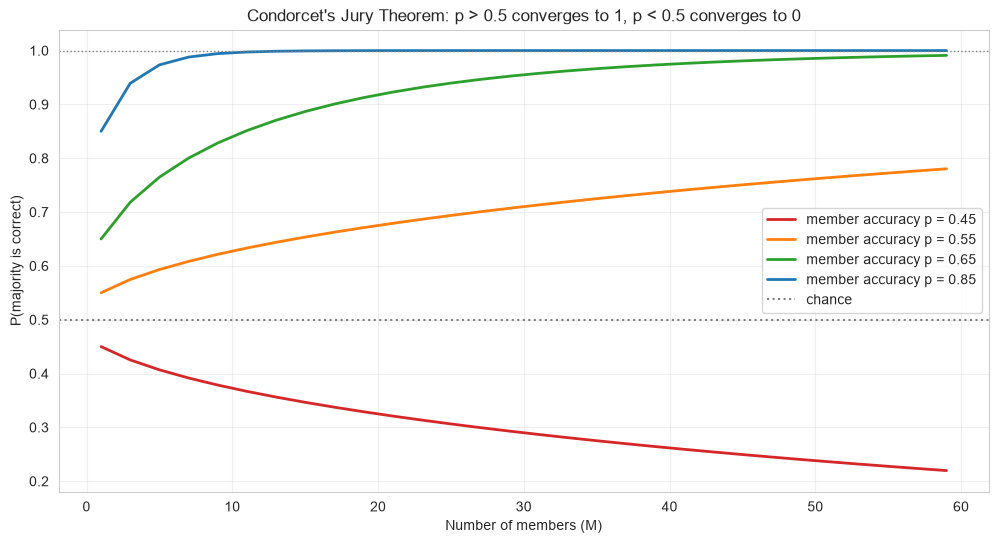

💡 The jury theorem, read as ensemble design:
   p > 0.5  → more (independent) members monotonically help
   p < 0.5  → more members make it WORSE - a below-chance member poisons the vote
   p ≈ 0.5  → the vote stays a coin flip; ensemble power comes from member quality first


In [2]:
# Condorcet's jury theorem: majority accuracy vs panel size, per member quality
M_values = np.arange(1, 61, 2)                       # odd panels: no vote ties
p_values = [0.45, 0.55, 0.65, 0.85]
colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']

plt.figure(figsize=(12, 6))
for p, color in zip(p_values, colors):
    majority_probs = [binom.sf(M // 2, M, p) for M in M_values]   # P(X > M/2)
    plt.plot(M_values, majority_probs, color=color, linewidth=2,
             label=f'member accuracy p = {p}')

plt.axhline(y=0.5, color='gray', linestyle=':', linewidth=1.5, label='chance')
plt.axhline(y=1.0, color='gray', linestyle=':', linewidth=1.0)
plt.xlabel('Number of members (M)')
plt.ylabel('P(majority is correct)')
plt.title("Condorcet's Jury Theorem: p > 0.5 converges to 1, p < 0.5 converges to 0")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("💡 The jury theorem, read as ensemble design:")
print("   p > 0.5  → more (independent) members monotonically help")
print("   p < 0.5  → more members make it WORSE - a below-chance member poisons the vote")
print("   p ≈ 0.5  → the vote stays a coin flip; ensemble power comes from member quality first")

### The Ambiguity Decomposition, Verified Numerically

The identity $\bar{E} = E + A$ holds for squared loss on averaged predictions. Applied to soft voting: treat each member's class probabilities $p_m$ as its "prediction", $\bar{p}$ as their average, and measure squared error against the one-hot targets. The three quantities must then satisfy:

$$\bar{E} = E + A \qquad \text{with} \qquad A = \frac{1}{M}\sum_m \big(p_m - \bar{p}\big)^2$$

The demo fits four heterogeneous scratch members (linear, tree, instance-based, forest - one per bias family) on interleaved moons and checks the identity to machine precision.

In [3]:
# Verify the ambiguity decomposition on soft-voted probabilities
import sys
sys.path.append('../src')

from models.linear_models import LogisticRegressionScratch
from models.tree_models import DecisionTreeClassifierScratch
from models.knn_models import KNNClassifierScratch
from models.ensemble_models import (
    RandomForestClassifierScratch, VotingEnsembleClassifierScratch,
)

X_moon, y_moon = make_moons(n_samples=400, noise=0.22, random_state=42)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_moon, y_moon, test_size=0.3, random_state=42, stratify=y_moon
)

panel = [
    ('linear', LogisticRegressionScratch(learning_rate=0.1, max_iter=300)),
    ('tree', DecisionTreeClassifierScratch(max_depth=3)),
    ('knn', KNNClassifierScratch(n_neighbors=5)),
    ('forest', RandomForestClassifierScratch(n_estimators=25, random_state=42)),
]

probas = []
for name, member in panel:
    member.fit(Xm_tr, ym_tr)
    probas.append(member.predict_proba(Xm_te))          # (n_test, 2), member's own class order
probas = np.stack(probas)                                # (M, n_test, 2)

p_bar = probas.mean(axis=0)                              # the soft-vote average, by hand
Y_onehot = np.eye(2)[ym_te]                              # one-hot targets

E = np.mean((p_bar - Y_onehot) ** 2)                     # ensemble error
E_bar = np.mean((probas - Y_onehot) ** 2)                # average member error
A = np.mean((probas - p_bar) ** 2)                       # ambiguity (diversity)

print("Ambiguity decomposition (Krogh & Vedelsby 1995):")
print(f"  E  (ensemble error)      = {E:.6f}")
print(f"  E_bar (avg member error) = {E_bar:.6f}")
print(f"  A  (diversity)           = {A:.6f}")
print(f"  E_bar - A                = {E_bar - A:.6f}   (must equal E)")
print(f"  residual |E - (E_bar-A)| = {abs(E - (E_bar - A)):.2e}   <- machine precision")

print("\nAlso true for the hard-vote accuracy path:")
acc_members = {name: np.mean(est.predict(Xm_te) == ym_te) for name, est in panel}
vote_soft = VotingEnsembleClassifierScratch(estimators=panel, voting='soft').fit(Xm_tr, ym_tr)
acc_soft = vote_soft.score(Xm_te, ym_te)
for name, acc in acc_members.items():
    print(f"  {name:>8} member: {acc:.3f}")
print(f"  {'soft vote':>8} panel: {acc_soft:.3f}   (beats its average member, not always its best)")

Ambiguity decomposition (Krogh & Vedelsby 1995):
  E  (ensemble error)      = 0.045553
  E_bar (avg member error) = 0.065290
  A  (diversity)           = 0.019737
  E_bar - A                = 0.045553   (must equal E)
  residual |E - (E_bar-A)| = 0.00e+00   <- machine precision

Also true for the hard-vote accuracy path:
    linear member: 0.875
      tree member: 0.925
       knn member: 0.917
    forest member: 0.942
  soft vote panel: 0.958   (beats its average member, not always its best)


### Hard vs Soft Voting

**Hard voting** - majority of predicted labels:

$$\hat{y} = \mathrm{mode}\big\{\hat{y}_1(x), \hat{y}_2(x), \ldots, \hat{y}_M(x)\big\}$$

**Soft voting** - argmax of the averaged class probabilities:

$$\hat{y} = \arg\max_k \; \frac{1}{M}\sum_m p_m(k \mid x)$$

Soft voting carries more information per vote: a confident $p = 0.95$ outweighs two lukewarm $p = 0.40$s, where hard voting counts all three as one label each. That is also its failure mode - **probabilities must mean something**. A member whose probabilities are badly miscalibrated (a vote-fraction forest, an overconfident tree) injects confidence the labels do not support. Rule of thumb from the scikit-learn docs: prefer `soft` for *well-calibrated* members; fall back to `hard` otherwise.

**Ties and weights.** Both engines break exact ties the same way: `argmax` returns the first maximal column, i.e. the **lowest class label wins** (scikit-learn's `VotingClassifier` and the scratch twin behave identically here). With `weights = [w_1, \ldots, w_M]`, hard voting tallies $w_m$ per label and soft voting averages $w_m p_m(k|x)$ normalized by $\sum_m w_m$.

The demo below is hand-checkable: one confident member and two lukewarm ones. Hard votes go 1-0-0 and answer 0; soft averages to 0.583 and answers 1.

In [4]:
# Hard vs soft divergence: one confident member vs two lukewarm ones
class FixedProbaMember:
    # A minimal sklearn-style member with fixed probabilities - enough public
    # API (fit / predict / predict_proba / classes_) for the scratch twin.
    def __init__(self, proba):
        self.proba = np.asarray(proba, dtype=float)

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.classes_[self.proba.argmax()]

    def predict_proba(self, X):
        return np.tile(self.proba, (len(X), 1))


tiny_members = [
    ('confident', FixedProbaMember([0.05, 0.95])),   # label 1, p = 0.95
    ('lukewarm A', FixedProbaMember([0.60, 0.40])),  # label 0, p = 0.60
    ('lukewarm B', FixedProbaMember([0.60, 0.40])),  # label 0, p = 0.60
]

X_tiny = np.zeros((1, 2))
y_tiny = np.array([0, 1])                                # both classes seen at fit

vote_hard = VotingEnsembleClassifierScratch(estimators=tiny_members, voting='hard').fit(X_tiny, y_tiny)
vote_soft = VotingEnsembleClassifierScratch(estimators=tiny_members, voting='soft').fit(X_tiny, y_tiny)

print("Hand-checkable divergence (one sample, classes {0, 1}):")
print("  member votes:   confident -> 1 (p=0.95), lukewarm A -> 0 (p=0.60), lukewarm B -> 0 (p=0.60)")
print(f"  HARD answer:    {vote_hard.predict(X_tiny)[0]}   (labels 1-0-0: majority 0)")
print(f"  SOFT answer:    {vote_soft.predict(X_tiny)[0]}   (avg p(1) = (0.95+0.40+0.40)/3 = {np.mean([0.95, 0.40, 0.40]):.3f} -> 1)")
print(f"  soft probas:    {vote_soft.predict_proba(X_tiny)[0]}")
print("\n💡 The confident member's 0.95 outweighs two lukewarm 0.60s under soft voting,")
print("   but every vote counts the same under hard voting. That is the whole difference.")

Hand-checkable divergence (one sample, classes {0, 1}):
  member votes:   confident -> 1 (p=0.95), lukewarm A -> 0 (p=0.60), lukewarm B -> 0 (p=0.60)
  HARD answer:    0   (labels 1-0-0: majority 0)
  SOFT answer:    1   (avg p(1) = (0.95+0.40+0.40)/3 = 0.583 -> 1)
  soft probas:    [0.41666667 0.58333333]

💡 The confident member's 0.95 outweighs two lukewarm 0.60s under soft voting,
   but every vote counts the same under hard voting. That is the whole difference.


### Stacking Mechanics: Out-of-Fold Meta-Features

The correct stacking recipe, which `StackingClassifier` automates:

1. Split the training data into $K$ folds (stratified by default for classifiers)
2. For each fold: fit every member on the other $K-1$ folds, predict on the held-out fold
3. Concatenate the held-out predictions - now every training row has a prediction made **without** seeing it ($M$ meta-features per row)
4. Fit the meta-estimator $g$ on those out-of-fold meta-features
5. Refit every member on the **full** training data (deployment-facing members)
6. At prediction time: run the refit members, feed their predictions to $g$

Step 2-4 is where the honesty lives. The degenerate alternative - fitting $g$ on each member's in-sample predictions - reports member errors near zero and teaches $g$ to over-trust whichever member memorizes most. The manual build in §6.3 shows both side by side.

Two sklearn implementation details worth knowing up front:

- **Binary probabilities are collinear**: $p_0 + p_1 = 1$, so `StackingClassifier` drops the first column of a binary member's `predict_proba` when `stack_method='auto'` resolves to probabilities (documented in the API notes)
- **The meta-learner should stay simple** (regularized logistic regression is the default): its input is only $M$ numbers per row, and a complex $g$ on tiny meta-features overfits the panel instead of the data

---

## 3. Assumptions & Requirements

### Critical Assumptions

#### ✅ 1. **Every Member Beats Chance**
Condorcet's theorem runs forward from member quality: members at $p \le 0.5$ *hurt* as the panel grows. A single broken member can be outvoted, a *majority* of broken members cannot be.
- **Test**: score every member on a validation split before ensembling; anything at or below chance gets fixed or dropped
- **Fix**: `'drop'` the member via `set_params`, or repair its preprocessing (scaling for KNN/logistic members)

#### ✅ 2. **Member Errors Decorrelate**
The ambiguity decomposition says ensemble error = average member error − diversity. Members that fail on the same rows (same family, same features, same seed, same preprocessing) have $A \approx 0$ and the ensemble repeats their shared mistakes.
- **Test**: the pairwise agreement matrix (§10) - members that agree on $> 95\%$ of test rows are near-duplicates
- **Fix**: one member per bias family (linear / tree / instance-based / probabilistic), or different feature subsets

#### ✅ 3. **Comparable Class Alignment Across Members (soft voting)**
Averaging $p_m(k \mid x)$ across members only means something if every member's probability columns refer to the same class. scikit-learn's `VotingClassifier` encodes labels internally (`le_`) and assumes member `classes_` are consistent; the scratch twin remaps every member's probability columns through that member's own `classes_` by value.
- **Test**: `vote.classes_` and each member's `classes_` must cover the same label set
- **Fix**: fit all members on the same `y`; non-contiguous or string labels are fine if every member sees them

#### ✅ 4. **Calibrated Probabilities for Soft Voting (and Stacking)**
Soft voting and probability-based stacking inherit each member's calibration. Vote-fraction probabilities (forests) and maximized-likelihood probabilities (Naive Bayes) are systematically overconfident in different ways.
- **Test**: `calibration_curve` per member before trusting soft votes
- **Fix**: `CalibratedClassifierCV` per member, or use `hard` voting

#### ✅ 5. **Enough Data for the Meta-Level (stacking)**
Out-of-fold meta-features cost the members $K$ partial fits, and the meta-estimator sees only $n$ rows of $M$-dimensional (often 2-3 column) input. On small $n$ the meta-estimator memorizes fold noise.
- **Rule of thumb**: stacking earns its keep in the hundreds-of-rows-and-up regime; below that, soft voting is the safer merge

### What the Combination Itself Requires

| Requirement | Why | What breaks without it |
|---|---|---|
| Labeled, supervised data | members must be trained; nothing is learned from unlabeled rows here | not applicable |
| All members fit/predict the same feature matrix | the merge is pointwise per row | shape mismatches raise loudly |
| Member `predict_proba` for soft/stacking | the average needs probability columns | sklearn raises; the twin raises at fit |
| Member preprocessing where the member needs it | scaling belongs to the member, not the ensemble | KNN/logistic members dominate or drown on mixed scales |
| Deterministic seeds in members | reproducible panels → reproducible votes | results wobble run to run |

### Key Differences from Bagging and Boosting

| Aspect | Bagging (04) | Boosting (08) | Voting / Stacking (16) |
|---|---|---|---|
| **Members** | same model, resampled data | same shallow model, sequential | different model families |
| **Diversity source** | resampling (+ feature subspace in RF) | residuals of previous stages | family differences |
| **Combination** | fixed (vote / mean) | additive with learned rate | fixed rule (voting) or learned $g$ (stacking) |
| **Member count** | 50-500 | 100-2000 stages | usually 3-6 |
| **Parallel training** | ✅ perfect | ❌ sequential | ✅ per member |
| **New preprocessing per member** | ❌ (one recipe) | ❌ | ✅ (each member brings its own) |

> **The demo that follows** builds a heterogeneous panel where every member needs different preprocessing - a scaled linear pipeline, an unscaled tree, a scaled instance-based model - which is exactly the degree of freedom voting has and bagging does not.

## 4. When to Use This Algorithm

### ✅ Use Voting / Stacking When:

1. **You already have several decent, different models**
   - One linear, one tree, one instance-based, one probabilistic - built for other reasons
   - Merging costs nothing to design and often buys 1-3 accuracy points

2. **Member errors decorrelate and each member is above chance**
   - The two conditions that make any ensemble math work (§2)

3. **You need the last margin of accuracy and can afford the latency**
   - Prediction costs the sum of members; stacking adds only the (tiny) meta-estimator

4. **Robustness to single-model failure matters**
   - A preprocessing bug, a drifted feature, an unlucky seed - the merged verdict survives what one member does not

5. **Interpretability requirements are per-member, not global**
   - You can still explain each member's reasoning; the vote is arithmetic, not a black box (stacking weakens this - $g$ adds one more layer)

### ❌ Avoid Voting / Stacking When:

1. **One member dominates everywhere**
   - If the single best model wins on every split, the panel is overhead. Ship the best member
   - Test it: `ensemble accuracy - best member accuracy` on a few seeds

2. **Members are near-duplicates**
   - Three logistic regressions with different `C` make one mistake three times. No diversity, no gain

3. **Latency or memory budgets are tight**
   - M members means M fits at train and M predictions at inference. A single boosted tree often matches at a fraction of the cost

4. **The data is small**
   - Stacking on tens of rows overfits the folds; soft voting is the safer merge below a few hundred rows

5. **A single model class is clearly right**
   - If the problem is linear, one regularized linear model is the honest answer (same logic as notebook 04's "forests do not fix the wrong model class")

### Voting vs Stacking vs Best Single Model

| Aspect | Hard voting | Soft voting | Stacking | Best single member |
|---|---|---|---|---|
| **Information per vote** | label only | full distribution | full distribution + interactions | all of the model |
| **Needs calibration** | ❌ no | ✅ yes | ✅ yes (if proba-based) | member-dependent |
| **Extra fit cost** | none | none | $K$ × member fits | none |
| **Learned parameters** | 0 | 0 (weights hand-set) | $g$'s parameters | member's own |
| **Overfit risk** | lowest | low | medium (leakage class) | member's own |
| **When it wins** | mixed-quality members | calibrated members | large data, strong members | when the panel is weak or redundant |

### Voting vs Bagging vs Boosting (the family-level choice)

**vs Bagging (notebook 04):**
- Same model resampled vs different models independent: bagging converts a single unstable learner's variance into stability; voting merges *already-stable* models of different biases
- Bagging needs no member tuning (all members identical); voting's member *selection* is the tuning

**vs Boosting (notebooks 08-11):**
- Boosting attacks bias with sequential corrections and usually wins raw accuracy on tabular data; voting attacks error correlation and usually wins robustness
- Boosting is tuning-heavy (learning rate, depth, stages); voting is design-heavy (which members)

**vs Both:**
- The members can themselves be ensembles - a panel of RF + GB + a linear model is a common stacking input (§10 does exactly this)

---

## 5. Implementation from Scratch (NumPy)

### Why Implement an Ensemble from Scratch?

- The combination rule looks trivial in a textbook - until you have to make *heterogeneous* members agree on class order, handle tied votes, and fail loudly when a member breaks the contract
- The merge is inspectable: the vote matrix and the probability matrix are concrete objects you can print, not an abstraction
- It pins down the exact tie-breaking and remapping conventions scikit-learn also uses - the conventions you would otherwise discover only through a debugging session

The from-scratch twin lives in `src/models/ensemble_models.py` as **`VotingEnsembleClassifierScratch`**. It is a hard/soft voting classifier over *heterogeneous* scikit-style members: each member is given as a `(name, estimator)` template tuple (like sklearn's `VotingClassifier`), deep-copied at fit time so every member trains from fresh state. Members only need `fit` + `predict` (hard) or additionally `predict_proba` (soft).

What the twin deliberately leaves out (documented in the module):
- **No `weights`** - merging is uniform; weighted voting is a two-line exercise on top of the hand-built tally below
- **No regressor twin** - voting/stacking for regression is shown with sklearn only (§10 Example 2)
- **No stacking** - there is no meta-estimator to learn the combination; the twin's combination rule is fixed
- **Sequential member training** - no `n_jobs`; members are cheap by design
- Members must predict within the ensemble's `classes_` - anything else raises a contract violation instead of being silently mis-bucketed

In [5]:
# Import our from-scratch implementations
import sys
sys.path.append('../src')

from models.ensemble_models import VotingEnsembleClassifierScratch
from models.linear_models import LogisticRegressionScratch
from models.tree_models import DecisionTreeClassifierScratch
from models.knn_models import KNNClassifierScratch


def fresh_panel():
    # Heterogeneous panel, one member per bias family (the app's voting card
    # uses the same design: linear + recursive-rule + instance-based).
    # Fresh templates every call - the twin deep-copies at fit time, but
    # starting unfitted keeps the "templates stay untouched" demo honest.
    return [
        ('linear', LogisticRegressionScratch(learning_rate=0.1, max_iter=300)),
        ('tree', DecisionTreeClassifierScratch(max_depth=3)),
        ('knn', KNNClassifierScratch(n_neighbors=5)),
    ]


print("✅ Imported custom Voting Ensemble implementation!")
print("\nAvailable class:")
print("  VotingEnsembleClassifierScratch")
print("\nIt wraps ANY scikit-style members (scratch or sklearn) that implement")
print("fit/predict - and predict_proba for soft voting - and merges their")
print("verdicts by majority vote or averaged probabilities.")

✅ Imported custom Voting Ensemble implementation!

Available class:
  VotingEnsembleClassifierScratch

It wraps ANY scikit-style members (scratch or sklearn) that implement
fit/predict - and predict_proba for soft voting - and merges their
verdicts by majority vote or averaged probabilities.


### How the Scratch Version Works (a guided tour)

Read `src/models/ensemble_models.py` alongside these facts:

**1. Fit trains fresh deep-copies of the templates (`fit`).**
Each `(name, estimator)` template is deep-copied, then fitted on the full training data. The originals are never touched - the fitted members live in `estimators_`, addressable by name through `named_estimators_`. This is the same contract sklearn's `VotingClassifier` honors, and it is why the same template list can seed several ensembles (hard and soft) without interference.

**2. The vote matrix counts labels, not booleans (`_vote_matrix`).**
For hard voting, every member's `predict` output is mapped into class-column space with `searchsorted` against the ensemble's `classes_`, and tallied with `np.add.at` into a `(n_samples, n_classes)` matrix. A member that predicts a label outside `classes_` is a **contract violation** - the twin raises loudly rather than letting `searchsorted` silently bucket it into a neighboring class.

**3. The probability matrix averages with a value-based remap (`_proba_matrix`).**
For soft voting, each member's `predict_proba` columns are remapped through that member's **own** `classes_`: column `c` holds the probability of `member.classes_[c]`, so it is added to the ensemble column where that *value* belongs. In practice every member's `classes_` is sorted, which makes the remap a no-op - the twin still does it, because it costs nothing and makes mixed panels (scratch + sklearn members, non-contiguous labels) safe by construction.

**4. Ties resolve to the lowest class label (first-max `argmax`).**
Both `predict` paths end in `classes_[votes.argmax(axis=1)]`. NumPy's `argmax` returns the first maximal column, so an exact tie (2 members, votes 1-1) resolves to the lowest class index - **the same order-dependent rule sklearn uses**. With an even member count, ties are real; with an odd count they are not (Condorcet panels are sized odd on purpose).

**5. Soft voting validates its input loudly.**
`fit` rejects an empty member list, duplicate names, non-string names, an unknown `voting` value, and - for `soft` - any member without `predict_proba`. `predict_proba` on a hard-voting ensemble is defined (it returns the averaged probabilities) but is documented as not being the model's decision path: the hard vote ignores probabilities entirely.

**6. `score` is plain accuracy.**
`score(X, y)` = mean of correct predictions - matching the sklearn convention the app's metrics row consumes.

In [6]:
# Mechanism 1: fit trains fresh deep-copies; the templates are never touched
vote_soft = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='soft')
vote_soft.fit(Xm_tr, ym_tr)

print("Fitted ensemble structure:")
print(f"  classes_:        {vote_soft.classes_}")
print(f"  member_names_:   {vote_soft.member_names_}")
print(f"  estimators_:     {len(vote_soft.estimators_)} fitted members")

print("\nThe 'templates stay unfitted' contract:")
# The twin's fitted members are NOT the objects we passed in (fresh deep-copies):
panel_objects = fresh_panel()
vote_check = VotingEnsembleClassifierScratch(estimators=panel_objects, voting='hard').fit(Xm_tr, ym_tr)
for (name, template), fitted_name in zip(panel_objects, vote_check.member_names_):
    fitted = vote_check.named_estimators_[fitted_name]
    print(f"  {name:>7}: fitted member is the template object? {fitted is template}"
          f"  | template got fitted? {getattr(template, 'classes_', None) is not None}")

print("\nEach member trained on the full training data:")
accs = {name: est.score(Xm_te, ym_te) for name, est in vote_check.named_estimators_.items()}
for name, acc in accs.items():
    print(f"  {name:>7}: test accuracy {acc:.3f}")
print("💡 Every member is a full model on its own - the ensemble is only the merge.")

Fitted ensemble structure:
  classes_:        [0 1]
  member_names_:   ('linear', 'tree', 'knn')
  estimators_:     3 fitted members

The 'templates stay unfitted' contract:
   linear: fitted member is the template object? False  | template got fitted? False
     tree: fitted member is the template object? False  | template got fitted? False
      knn: fitted member is the template object? False  | template got fitted? False

Each member trained on the full training data:
   linear: test accuracy 0.875
     tree: test accuracy 0.925
      knn: test accuracy 0.917
💡 Every member is a full model on its own - the ensemble is only the merge.


In [7]:
# Mechanism 2: the vote matrix, reconstructed by hand
vote_hard = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='hard').fit(Xm_tr, ym_tr)

member_preds = {name: est.predict(Xm_te) for name, est in vote_hard.named_estimators_.items()}
n_show = 8

# Hand-built vote tally: one +1 per member into the predicted class's column
votes_hand = np.zeros((n_show, len(vote_hard.classes_)))
rows = []
for i in range(n_show):
    member_votes = {}
    for name, preds in member_preds.items():
        col = np.searchsorted(vote_hard.classes_, preds[i])
        votes_hand[i, col] += 1
        member_votes[name] = preds[i]
    rows.append(member_votes)

vote_df = pd.DataFrame(rows)
vote_df.insert(0, 'true class', ym_te[:n_show])
vote_df['vote tally (class 0, 1)'] = [f"({int(v[0])}, {int(v[1])})" for v in votes_hand]
vote_df['hand prediction'] = vote_hard.classes_[votes_hand.argmax(axis=1)]
vote_df['twin prediction'] = vote_hard.predict(Xm_te)[:n_show]
print("First 8 test rows - member votes and the tally:")
print(vote_df.to_string(index=False))

# Verify the FULL hand tally matches the twin on every test row:
votes_full = np.zeros((len(Xm_te), len(vote_hard.classes_)))
for name, preds in member_preds.items():
    cols = np.searchsorted(vote_hard.classes_, preds)
    np.add.at(votes_full, (np.arange(len(Xm_te)), cols), 1.0)
hand_pred_full = vote_hard.classes_[votes_full.argmax(axis=1)]
print(f"\nhand tally == twin predict() on all {len(Xm_te)} test rows: "
      f"{np.array_equal(hand_pred_full, vote_hard.predict(Xm_te))}")

print("\nThe tally is all a hard vote is: counts per class, argmax, done.")

First 8 test rows - member votes and the tally:
 true class  linear  tree  knn vote tally (class 0, 1)  hand prediction  twin prediction
          1       1     1    1                  (0, 3)                1                1
          0       0     0    0                  (3, 0)                0                0
          0       0     0    0                  (3, 0)                0                0
          1       1     1    0                  (1, 2)                1                1
          1       1     1    1                  (0, 3)                1                1
          0       0     0    0                  (3, 0)                0                0
          1       1     1    1                  (0, 3)                1                1
          0       0     0    0                  (3, 0)                0                0

hand tally == twin predict() on all 120 test rows: True

The tally is all a hard vote is: counts per class, argmax, done.


In [8]:
# Mechanism 2b: tie-breaking - and the loud contract violation
class ConstantMember:
    # Votes one fixed label on every row. fit/predict only (no proba) - fine for hard voting.
    def __init__(self, label):
        self.label = label

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return np.full(len(X), self.label, dtype=int)


tie_members = [('always-zero', ConstantMember(0)), ('always-one', ConstantMember(1))]
tie_vote = VotingEnsembleClassifierScratch(estimators=tie_members, voting='hard').fit(Xm_tr, ym_tr)
tie_pred = tie_vote.predict(Xm_te[:5])
print("Tie-breaking demo (2 members, votes always split 1-1):")
print(f"  tied votes on 5 rows -> {tie_pred}")
print("  argmax returns the FIRST maximal column -> the LOWEST class label (0) wins every tie")
print("  (scikit-learn's VotingClassifier follows the same first-max rule)")

print("\n" + "=" * 60)


class OutsiderMember(ConstantMember):
    # Predicts a label the ensemble never saw - a contract violation.
    def predict(self, X):
        return np.full(len(X), 99, dtype=int)


bad_vote = VotingEnsembleClassifierScratch(
    estimators=[('broken', OutsiderMember(0)), ('ok', ConstantMember(1))],
    voting='hard',
).fit(Xm_tr, ym_tr)

try:
    bad_vote.predict(Xm_te[:3])
except ValueError as exc:
    print("Contract violation is raised, not silently mis-bucketed:")
    print(f"  ValueError: {exc}")

Tie-breaking demo (2 members, votes always split 1-1):
  tied votes on 5 rows -> [0 0 0 0 0]
  argmax returns the FIRST maximal column -> the LOWEST class label (0) wins every tie
  (scikit-learn's VotingClassifier follows the same first-max rule)

Contract violation is raised, not silently mis-bucketed:
  ValueError: member 'broken' predicted labels outside the ensemble's classes_ [0, 1]: [np.int64(99)]


In [9]:
# Mechanism 3: the probability matrix, reconstructed by hand - with a remap forced
class ReversedOrderMember:
    # Declares classes_ in the order [20, 10] (unsorted!) with probability
    # columns in ITS OWN order. The twin remaps by VALUE, so the average
    # stays correct - this is the situation the remap exists for.
    def __init__(self, proba_20, proba_10):
        self.p20, self.p10 = proba_20, proba_10

    def fit(self, X, y):
        self.classes_ = np.array([20, 10])
        return self

    def predict(self, X):
        return self.classes_[np.array([self.p20, self.p10]).argmax()]

    def predict_proba(self, X):
        return np.tile([self.p20, self.p10], (len(X), 1))


class NormalOrderMember:
    # The conventional member: classes_ = [10, 20], columns in that order.
    def __init__(self, proba_10, proba_20):
        self.p10, self.p20 = proba_10, proba_20

    def fit(self, X, y):
        self.classes_ = np.array([10, 20])
        return self

    def predict(self, X):
        return self.classes_[np.array([self.p10, self.p20]).argmax()]

    def predict_proba(self, X):
        return np.tile([self.p10, self.p20], (len(X), 1))


remap_members = [
    ('reversed', ReversedOrderMember(proba_20=0.9, proba_10=0.1)),
    ('normal', NormalOrderMember(proba_10=0.2, proba_20=0.8)),
]
X_r = np.zeros((1, 2))
y_r = np.array([10, 20])

remap_vote = VotingEnsembleClassifierScratch(estimators=remap_members, voting='soft').fit(X_r, y_r)

# Hand average: place each member's probability where its VALUE says it belongs
ensemble_classes = remap_vote.classes_                    # [10, 20]
avg_hand = np.zeros(len(ensemble_classes))
for name, est in zip(remap_vote.member_names_, remap_vote.estimators_):
    proba = est.predict_proba(X_r)[0]
    for col, value in enumerate(est.classes_):
        avg_hand[np.searchsorted(ensemble_classes, value)] += proba[col]
avg_hand /= len(remap_members)

print("Probability remap demo (labels {10, 20}, one sample):")
print(f"  ensemble classes_:                {ensemble_classes}")
print(f"  'reversed' member classes_:       {remap_vote.named_estimators_['reversed'].classes_}"
      f"  (columns hold [p(20), p(10)])")
print(f"  hand average via value remap:     class 10 -> {avg_hand[0]:.3f}, class 20 -> {avg_hand[1]:.3f}")
print(f"  twin predict_proba:               {remap_vote.predict_proba(X_r)[0]}")
print(f"  match: {np.allclose(avg_hand, remap_vote.predict_proba(X_r)[0])}")
print("\n💡 Naive position-based averaging would add the reversed member's p(20)")
print("   onto class 10 - the value-based remap is what keeps mixed panels safe.")

print("\n" + "=" * 60)
print("Out-of-contract proba shape also raises loudly (from _proba_matrix):")


class BadShapeMember(NormalOrderMember):
    def predict_proba(self, X):
        return np.zeros((len(X), 5))            # wrong column count


try:
    VotingEnsembleClassifierScratch(
        estimators=[('bad', BadShapeMember(0.5, 0.5))], voting='soft'
    ).fit(X_r, y_r).predict(X_r)
except ValueError as exc:
    print(f"  ValueError: {exc}")

Probability remap demo (labels {10, 20}, one sample):
  ensemble classes_:                [10 20]
  'reversed' member classes_:       [20 10]  (columns hold [p(20), p(10)])
  hand average via value remap:     class 10 -> 0.150, class 20 -> 0.850
  twin predict_proba:               [0.15 0.85]
  match: True

💡 Naive position-based averaging would add the reversed member's p(20)
   onto class 10 - the value-based remap is what keeps mixed panels safe.

Out-of-contract proba shape also raises loudly (from _proba_matrix):
  ValueError: member 'bad' returned proba shaped (1, 5); expected (1, 2)


### Classification Example (From Scratch)

The interleaved-moons bench from §2, fitted with the heterogeneous scratch panel. The question the vote answers: does merging a linear, a depth-3 tree, and a 5-NN beat each of them - and do hard and soft agree on *where* they disagree?

In [10]:
# Hard and soft votes over the same heterogeneous scratch panel
vote_hard = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='hard').fit(Xm_tr, ym_tr)
vote_soft = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='soft').fit(Xm_tr, ym_tr)

print("=" * 60)
print("HETEROGENEOUS VOTING ENSEMBLE (FROM SCRATCH)")
print("=" * 60)
print(f"\n📊 Dataset: interleaved moons, {len(Xm_tr)} train / {len(Xm_te)} test")

print("\n🎯 Member accuracies (each fitted member of the soft ensemble):")
for name, est in zip(vote_soft.member_names_, vote_soft.estimators_):
    print(f"  {name:>7}: {est.score(Xm_te, ym_te):.4f}")

print("\n🗳️ Ensemble accuracies:")
print(f"  hard vote: {vote_hard.score(Xm_te, ym_te):.4f}")
print(f"  soft vote: {vote_soft.score(Xm_te, ym_te):.4f}")

hard_pred = vote_hard.predict(Xm_te)
soft_pred = vote_soft.predict(Xm_te)
print(f"\n🤝 hard/soft prediction agreement: {np.mean(hard_pred == soft_pred):.1%} of test rows")
print("   (high agreement = members are calibrated enough that labels and")
print("    probabilities tell the same story; divergences cluster where")
print("    one member is confident and the other two lukewarm)")

HETEROGENEOUS VOTING ENSEMBLE (FROM SCRATCH)

📊 Dataset: interleaved moons, 280 train / 120 test

🎯 Member accuracies (each fitted member of the soft ensemble):
   linear: 0.8750
     tree: 0.9250
      knn: 0.9167

🗳️ Ensemble accuracies:
  hard vote: 0.9250
  soft vote: 0.9500

🤝 hard/soft prediction agreement: 95.8% of test rows
   (high agreement = members are calibrated enough that labels and
    probabilities tell the same story; divergences cluster where
    one member is confident and the other two lukewarm)


In [11]:
# Disagreement analysis: what happens on rows where the members split?
member_preds = pd.DataFrame({
    name: est.predict(Xm_te) for name, est in zip(vote_soft.member_names_, vote_soft.estimators_)
})
disagree = member_preds.nunique(axis=1) > 1
n_disagree = int(disagree.sum())

print(f"Members disagree on {n_disagree}/{len(Xm_te)} test rows ({n_disagree / len(Xm_te):.1%})")
print("\nOn the FULL test set vs the DISAGREEMENT subset only:")

acc_table = {'member': [], 'full test': [], 'on disagreement rows': []}
for name, est in zip(vote_soft.member_names_, vote_soft.estimators_):
    preds = member_preds[name].to_numpy()
    acc_table['member'].append(name)
    acc_table['full test'].append(np.mean(preds == ym_te))
    acc_table['on disagreement rows'].append(np.mean(preds[disagree] == ym_te[disagree]))
acc_table['member'].append('soft vote (the merge)')
acc_table['full test'].append(vote_soft.score(Xm_te, ym_te))
acc_table['on disagreement rows'].append(np.mean(soft_pred[disagree] == ym_te[disagree]))

print(pd.DataFrame(acc_table).to_string(index=False))

print("\n💡 On agreeing rows every member is right together - nothing to gain.")
print("   On disagreement rows the merge chooses, and it does better than")
print("   each individual member there. That subset IS where ensembles earn.")

Members disagree on 21/120 test rows (17.5%)

On the FULL test set vs the DISAGREEMENT subset only:
               member  full test  on disagreement rows
               linear   0.875000              0.380952
                 tree   0.925000              0.666667
                  knn   0.916667              0.619048
soft vote (the merge)   0.950000              0.809524

💡 On agreeing rows every member is right together - nothing to gain.
   On disagreement rows the merge chooses, and it does better than
   each individual member there. That subset IS where ensembles earn.


---

## 6. Implementation with Scikit-learn

scikit-learn ships the three combination strategies as meta-estimators in `sklearn.ensemble`. A few API facts worth pinning before the first fit (verified against the pinned scikit-learn 1.9):

- `VotingClassifier(estimators, voting='hard', weights=None, ...)`: the **default is `hard`** - soft voting is opt-in, and it requires every member to expose `predict_proba`. Members are fitted on internally integer-encoded labels (`le_` attribute handles the mapping back)
- `BaggingClassifier(estimator=None, n_estimators=10, ...)`: the default base is a full `DecisionTreeClassifier` and the default panel is only **10** members - both almost always worth changing. `max_features` < 1.0 turns it into the random-subspaces method
- `StackingClassifier(estimators, final_estimator=None, cv=None, ...)`: the default final estimator is a `LogisticRegression`, the default `cv` is 5-fold (stratified for classifiers), and members are refit on the full training data after the meta-estimator sees out-of-fold predictions. Binary members contribute their probability columns minus the first (they are collinear)
- All three accept `n_jobs` for the member fits, and all three fit *clones* of the member templates - the originals stay untouched

### Voting with scikit-learn

The same moons bench, the same three bias families - now with sklearn's engines inside the panel. Then the **dual-engine check**: the scratch twin (scratch members) and `VotingClassifier` (sklearn members) on the same data. The members differ by engine, so accuracies will not match exactly; what must match is the *behavior of the merge* - the same fixed rules, the same tie-breaking.

In [12]:
# VotingClassifier on the same bench, then the dual-engine check
sk_members = [
    ('linear', LogisticRegression(max_iter=1000)),
    ('tree', DecisionTreeClassifier(max_depth=3, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
]

vc_hard = VotingClassifier(estimators=sk_members, voting='hard').fit(Xm_tr, ym_tr)
vc_soft = VotingClassifier(estimators=sk_members, voting='soft').fit(Xm_tr, ym_tr)

print("=" * 60)
print("VOTING CLASSIFIER (SCIKIT-LEARN)")
print("=" * 60)
print(f"\n🎯 sklearn members on moons:")
for name, est in zip(vc_soft.named_estimators_.keys(), vc_soft.estimators_):
    print(f"  {name:>7}: {est.score(Xm_te, ym_te):.4f}")
print(f"\n🗳️ sklearn ensemble:  hard {vc_hard.score(Xm_te, ym_te):.4f} | soft {vc_soft.score(Xm_te, ym_te):.4f}")

print("\n" + "=" * 60)
print("DUAL ENGINE: SCRATCH TWIN vs SCIKIT-LEARN")
print("=" * 60)
scratch_hard = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='hard').fit(Xm_tr, ym_tr)
scratch_soft = VotingEnsembleClassifierScratch(estimators=fresh_panel(), voting='soft').fit(Xm_tr, ym_tr)

rows = [
    {'engine': 'scratch twin (scratch members)', 'hard': scratch_hard.score(Xm_te, ym_te),
     'soft': scratch_soft.score(Xm_te, ym_te)},
    {'engine': 'sklearn VotingClassifier (sklearn members)', 'hard': vc_hard.score(Xm_te, ym_te),
     'soft': vc_soft.score(Xm_te, ym_te)},
]
print(pd.DataFrame(rows).to_string(index=False))

print("\n🔍 Reading the dual-engine numbers:")
print("  • accuracies differ because the MEMBER engines differ (scratch trees")
print("    split on gini count thresholds; sklearn trees on impurity with more heuristics)")
print("  • what agrees is the MERGE: same majority rule, same averaged-probability")
print("    rule, same first-max tie-breaking - the twin's conventions are sklearn's")

# Where do the two soft engines disagree?
sk_soft_pred = vc_soft.predict(Xm_te)
sc_soft_pred = scratch_soft.predict(Xm_te)
print(f"\n  soft-vote prediction agreement across engines: {np.mean(sk_soft_pred == sc_soft_pred):.1%} of test rows")

VOTING CLASSIFIER (SCIKIT-LEARN)

🎯 sklearn members on moons:
   linear: 0.8917
     tree: 0.9167
      knn: 0.9167

🗳️ sklearn ensemble:  hard 0.9250 | soft 0.9500

DUAL ENGINE: SCRATCH TWIN vs SCIKIT-LEARN
                                    engine  hard  soft
            scratch twin (scratch members) 0.925  0.95
sklearn VotingClassifier (sklearn members) 0.925  0.95

🔍 Reading the dual-engine numbers:
  • accuracies differ because the MEMBER engines differ (scratch trees
    split on gini count thresholds; sklearn trees on impurity with more heuristics)
  • what agrees is the MERGE: same majority rule, same averaged-probability
    rule, same first-max tie-breaking - the twin's conventions are sklearn's

  soft-vote prediction agreement across engines: 100.0% of test rows


                    weights  test accuracy
          uniform [1, 1, 1]       0.950000
     trust linear [3, 1, 1]       0.941667
       trust tree [1, 3, 1]       0.933333
        trust knn [1, 1, 3]       0.925000
soft-pedal tree [1, 0.5, 1]       0.950000

best single member for reference: 0.9167


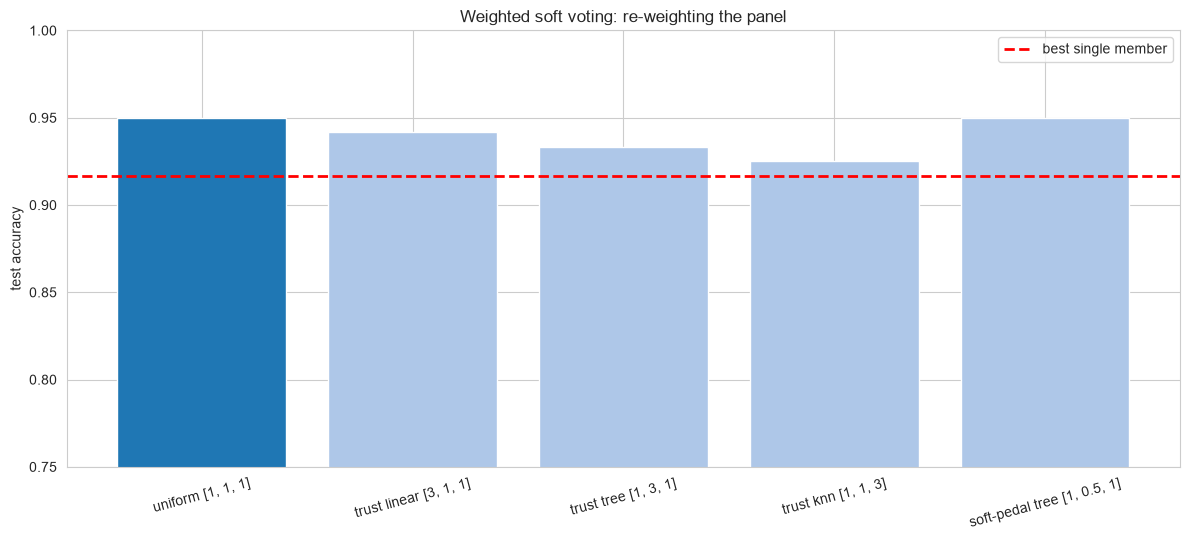

💡 Weights trade members against each other - and the spread across
   weightings is small on a healthy panel. If one weighting dominates,
   the other members may not be pulling their weight (see §9).


In [13]:
# Weighted soft voting: emphasize the member you trust
weight_variants = {
    'uniform [1, 1, 1]': [1, 1, 1],
    'trust linear [3, 1, 1]': [3, 1, 1],
    'trust tree [1, 3, 1]': [1, 3, 1],
    'trust knn [1, 1, 3]': [1, 1, 3],
    'soft-pedal tree [1, 0.5, 1]': [1, 0.5, 1],
}

results_w = []
for label, weights in weight_variants.items():
    vc_w = VotingClassifier(estimators=sk_members, voting='soft', weights=weights).fit(Xm_tr, ym_tr)
    results_w.append({'weights': label, 'test accuracy': vc_w.score(Xm_te, ym_te)})

best_single = max(
    (est.score(Xm_te, ym_te) for est in vc_soft.estimators_),
)
df_w = pd.DataFrame(results_w)
print(df_w.to_string(index=False))
print(f"\nbest single member for reference: {best_single:.4f}")

fig, ax = plt.subplots(figsize=(12, 5.5))
colors_w = ['#1f77b4' if 'uniform' in w else '#aec7e8' for w in df_w['weights']]
ax.bar(df_w['weights'], df_w['test accuracy'], color=colors_w)
ax.axhline(y=best_single, color='red', linestyle='--', linewidth=2, label='best single member')
ax.set_ylim(0.75, 1.0)
ax.set_ylabel('test accuracy')
ax.set_title('Weighted soft voting: re-weighting the panel')
ax.tick_params(axis='x', rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

print("💡 Weights trade members against each other - and the spread across")
print("   weightings is small on a healthy panel. If one weighting dominates,")
print("   the other members may not be pulling their weight (see §9).")

after set_params(tree='drop'): 2 members remain (test acc 0.9500)

MEMBER vs ENSEMBLE - THE HONEST BAR CHART


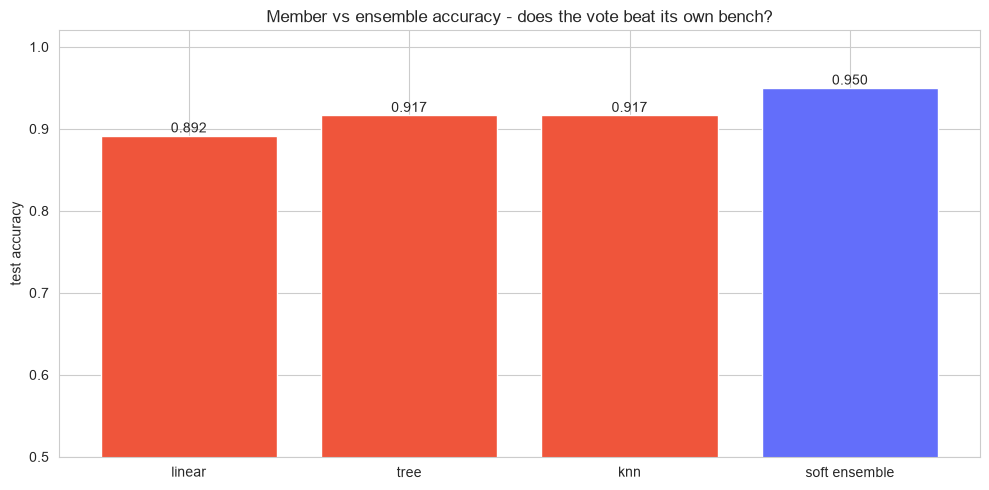

✅ the ensemble beats its best member by 0.0333
   Averaging is a bet on decorrelated errors - diversity is not free,
   and a panel with a weak member can underperform its own bench.


In [14]:
# Dropping a member, and the honest member-vs-ensemble bar chart
vc_drop = VotingClassifier(estimators=sk_members, voting='soft')
vc_drop.set_params(tree='drop')                     # sklearn's escape hatch
vc_drop.fit(Xm_tr, ym_tr)
print(f"after set_params(tree='drop'): {len(vc_drop.estimators_)} members remain "
      f"(test acc {vc_drop.score(Xm_te, ym_te):.4f})")

print("\n" + "=" * 60)
print("MEMBER vs ENSEMBLE - THE HONEST BAR CHART")
print("=" * 60)

names, accs = [], []
for name, est in zip(vc_soft.named_estimators_.keys(), vc_soft.estimators_):
    names.append(name)
    accs.append(est.score(Xm_te, ym_te))
names += ['soft ensemble']
accs.append(vc_soft.score(Xm_te, ym_te))

fig, ax = plt.subplots(figsize=(10, 5))
colors_me = ['#EF553B'] * 3 + ['#636EFA']
ax.bar(names, accs, color=colors_me)
for i, acc in enumerate(accs):
    ax.text(i, acc + 0.004, f"{acc:.3f}", ha='center', fontsize=10)
ax.set_ylim(min(0.5, min(accs) - 0.05), 1.02)
ax.set_ylabel('test accuracy')
ax.set_title('Member vs ensemble accuracy - does the vote beat its own bench?')
plt.tight_layout()
plt.show()

ensemble_gain = accs[-1] - max(accs[:-1])
if ensemble_gain > 0:
    print(f"✅ the ensemble beats its best member by {ensemble_gain:.4f}")
else:
    print(f"⚠️ the ensemble LOSES to its best member by {-ensemble_gain:.4f}")
print("   Averaging is a bet on decorrelated errors - diversity is not free,")
print("   and a panel with a weak member can underperform its own bench.")

### Bagging Beyond Forests (scikit-learn only)

Notebook 04 covered bagging *theory* and its flagship instance. `BaggingClassifier` is the general wrapper: **any** scikit-style base estimator can be bagged. The experiment that makes the concept concrete (Breiman 1996): bagging converts an **unstable** learner's variance into stability, and does essentially nothing for a **stable** one.

- Deep decision trees are unstable: a small row perturbation can change the root split and cascade down the whole tree → bagging helps a lot
- Logistic regression is stable: refit on a resample, the coefficients barely move → bagging buys (almost) nothing
- KNN is stable in the same sense (predictions move only when the neighborhood membership changes) → little to no gain

Random Forest is this wrapper with one extra trick - **per-node** feature subsampling - which decorrelates the members far more strongly than row resampling alone.

In [15]:
# Bagging meta-estimator: unstable vs stable bases
bases = {
    'deep tree (unstable)': DecisionTreeClassifier(random_state=42),
    'logistic (stable)': LogisticRegression(max_iter=1000),
    '5-NN (stable)': KNeighborsClassifier(n_neighbors=5),
}

rows_b = []
for name, base in bases.items():
    fresh_base = type(base)(**base.get_params())
    alone = fresh_base.fit(Xm_tr, ym_tr)
    bag = BaggingClassifier(estimator=base, n_estimators=50, oob_score=True,
                            random_state=42, n_jobs=-1).fit(Xm_tr, ym_tr)
    rows_b.append({
        'base': name,
        'alone (test)': alone.score(Xm_te, ym_te),
        'bagged x50 (test)': bag.score(Xm_te, ym_te),
        'bagged OOB': bag.oob_score_,
        'gain': bag.score(Xm_te, ym_te) - alone.score(Xm_te, ym_te),
    })

df_bag = pd.DataFrame(rows_b)
print(df_bag.to_string(index=False))

print("\n💡 Bagging pays where the base is unstable: the deep tree gains the")
print("   most, while logistic and KNN move within noise. The instability IS")
print("   the fuel - a stable learner has no variance for the average to cancel.")

print("\nRandom Forest is the specialization: bagged trees + PER-NODE feature")
print("subsampling (a stronger decorrelator than the per-estimator subset")
print("BaggingClassifier applies). Same wrapper, stronger randomness:")
rf_ref = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1).fit(Xm_tr, ym_tr)
bag_subspace = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50, max_features=0.5, random_state=42, n_jobs=-1,
).fit(Xm_tr, ym_tr)
print(f"  RandomForestClassifier(50):        {rf_ref.score(Xm_te, ym_te):.4f}")
print(f"  BaggingClassifier(tree, max_feat=0.5): {bag_subspace.score(Xm_te, ym_te):.4f}")

                base  alone (test)  bagged x50 (test)  bagged OOB      gain
deep tree (unstable)      0.925000           0.933333    0.950000  0.008333
   logistic (stable)      0.891667           0.883333    0.807143 -0.008333
       5-NN (stable)      0.916667           0.908333    0.964286 -0.008333

💡 Bagging pays where the base is unstable: the deep tree gains the
   most, while logistic and KNN move within noise. The instability IS
   the fuel - a stable learner has no variance for the average to cancel.

Random Forest is the specialization: bagged trees + PER-NODE feature
subsampling (a stronger decorrelator than the per-estimator subset
BaggingClassifier applies). Same wrapper, stronger randomness:
  RandomForestClassifier(50):        0.9417
  BaggingClassifier(tree, max_feat=0.5): 0.8667


### Stacking with scikit-learn (scikit-learn only)

No scratch twin exists for stacking - this subsection is scikit-learn only, in two steps: the **manual OOF build** (so the mechanism is visible and the leaky shortcut has a visible counter-example), then `StackingClassifier`, which automates the honest recipe.

In [16]:
# Manual stacking: out-of-fold meta-features vs the leaky shortcut
stack_members = [
    ('linear', Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))])),
    ('tree', DecisionTreeClassifier(max_depth=3, random_state=42)),
    ('knn', Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])),
]

K = 5
print(f"Building {K}-fold out-of-fold meta-features...")
oof_cols = []
for name, member in stack_members:
    oof_p1 = cross_val_predict(member, Xm_tr, ym_tr, cv=K, method='predict_proba')[:, 1]
    oof_cols.append(oof_p1)                      # binary: first column dropped (collinear)
meta_X_train = np.column_stack(oof_cols)
print(f"  meta-features: {meta_X_train.shape} - one honest probability per member per row")

# The meta-estimator learns whom to trust, from out-of-fold evidence only
meta_lr = LogisticRegression(max_iter=1000).fit(meta_X_train, ym_tr)
print(f"  learned trust (meta coefficients): "
      + ", ".join(f"{n}={c:+.2f}" for (n, _), c in zip(stack_members, meta_lr.coef_[0])))

# Deployment: refit members on the FULL training data, then predict via the meta-estimator
fitted_full = [(name, m.fit(Xm_tr, ym_tr)) for name, m in stack_members]
meta_X_test = np.column_stack([
    m.predict_proba(Xm_te)[:, 1] for _, m in fitted_full
])
manual_stack_pred = meta_lr.predict(meta_X_test)
manual_stack_acc = np.mean(manual_stack_pred == ym_te)

print("\n" + "=" * 60)
print("THE LEAKY SHORTCUT: meta-features from IN-SAMPLE predictions")
print("=" * 60)
leak_meta_X = np.column_stack([
    m.predict_proba(Xm_tr)[:, 1] for _, m in fitted_full   # members score rows they trained on
])
meta_lr_leak = LogisticRegression(max_iter=1000).fit(leak_meta_X, ym_tr)
leak_train_acc = np.mean(meta_lr_leak.predict(leak_meta_X) == ym_tr)
leak_pred = meta_lr_leak.predict(meta_X_test)
leak_test_acc = np.mean(leak_pred == ym_te)

coef_honest = ", ".join(f"{n}={c:+.2f}" for (n, _), c in zip(stack_members, meta_lr.coef_[0]))
coef_leaky = ", ".join(f"{n}={c:+.2f}" for (n, _), c in zip(stack_members, meta_lr_leak.coef_[0]))
print(f"  honest meta coefficients:  {coef_honest}")
print(f"  leaky meta coefficients:   {coef_leaky}")

rows_stack = [
    {'stack variant': 'honest (out-of-fold meta-features)', 'test accuracy': manual_stack_acc},
    {'stack variant': 'leaky (in-sample meta-features)', 'test accuracy': leak_test_acc},
]
print(pd.DataFrame(rows_stack).to_string(index=False))
print(f"\n  leaky stack's TRAIN accuracy: {leak_train_acc:.4f}  <- inflated: members score")
print("  their own training rows near-perfectly, so g over-trusts whoever memorized most")
print("  (compare the two variants' learned coefficients - the leaky one is skewed)")

Building 5-fold out-of-fold meta-features...
  meta-features: (280, 3) - one honest probability per member per row
  learned trust (meta coefficients): linear=+0.78, tree=+1.35, knn=+4.52

THE LEAKY SHORTCUT: meta-features from IN-SAMPLE predictions
  honest meta coefficients:  linear=+0.78, tree=+1.35, knn=+4.52
  leaky meta coefficients:   linear=+0.43, tree=+1.78, knn=+5.01
                     stack variant  test accuracy
honest (out-of-fold meta-features)       0.941667
   leaky (in-sample meta-features)       0.941667

  leaky stack's TRAIN accuracy: 0.9679  <- inflated: members score
  their own training rows near-perfectly, so g over-trusts whoever memorized most
  (compare the two variants' learned coefficients - the leaky one is skewed)


In [17]:
# StackingClassifier: the same recipe, automated and correct
sc = StackingClassifier(
    estimators=stack_members,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
).fit(Xm_tr, ym_tr)

print("=" * 60)
print("STACKING CLASSIFIER (SCIKIT-LEARN)")
print("=" * 60)
print(f"\nstack_method_ (what each member contributed): {sc.stack_method_}")
print(f"final_estimator_: {type(sc.final_estimator_).__name__}")
print(f"learned trust (final_estimator_ coef_): "
      + ", ".join(f"{n}={c:+.2f}" for n, c in zip(sc.named_estimators_.keys(), sc.final_estimator_.coef_[0])))

# The three merges side by side, with the best member for reference
member_accs = {name: est.score(Xm_te, ym_te) for name, est in sc.named_estimators_.items()}
rows_merge = [
    {'model': 'best member', 'test accuracy': max(member_accs.values())},
    {'model': 'hard voting (sklearn)', 'test accuracy': vc_hard.score(Xm_te, ym_te)},
    {'model': 'soft voting (sklearn)', 'test accuracy': vc_soft.score(Xm_te, ym_te)},
    {'model': 'stacking (sklearn)', 'test accuracy': sc.score(Xm_te, ym_te)},
]
print("\n" + pd.DataFrame(rows_merge).to_string(index=False))

print("\n🔍 Reading the stacking numbers:")
print("  • stack_method_ shows 'auto' resolved to predict_proba for every member")
print("  • the meta coefficients are the LEARNED version of voting weights -")
print("    same idea as the weight sweep above, fitted instead of guessed")
print("  • stacking's extra fit cost is K x (member fits); prediction cost is")
print("    members + one tiny logistic regression")

STACKING CLASSIFIER (SCIKIT-LEARN)

stack_method_ (what each member contributed): ['predict_proba', 'predict_proba', 'predict_proba']
final_estimator_: LogisticRegression
learned trust (final_estimator_ coef_): linear=+0.78, tree=+1.35, knn=+4.52

                model  test accuracy
          best member       0.916667
hard voting (sklearn)       0.925000
soft voting (sklearn)       0.950000
   stacking (sklearn)       0.941667

🔍 Reading the stacking numbers:
  • stack_method_ shows 'auto' resolved to predict_proba for every member
  • the meta coefficients are the LEARNED version of voting weights -
    same idea as the weight sweep above, fitted instead of guessed
  • stacking's extra fit cost is K x (member fits); prediction cost is
    members + one tiny logistic regression


---

## 7. Hyperparameter Tuning

Each meta-estimator has a different tuning surface, and none of them is tuned the way a normal model is:

1. **Voting**: the real "hyperparameter" is the **member list** - which families, how many, and (soft) how weighted. `voting='hard' | 'soft'` is a one-bit choice that depends on member calibration
2. **Bagging**: `n_estimators` is the easy knob (more is always safe, it only costs time); `max_samples` / `max_features` trade member strength against diversity
3. **Stacking**: `cv` and the **meta-estimator choice** - which should stay simple. Member tuning matters as usual, inside each member

The experiments below reuse the moons bench and the same three bias families plus extras.

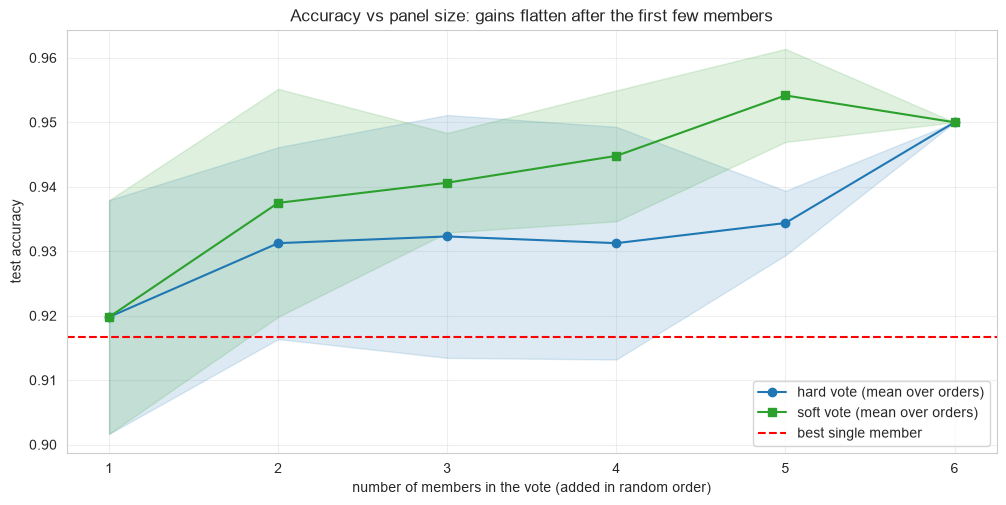

💡 Three lessons from the curve:
  1. Early members carry the gain; after ~4 the curve flattens (diminishing returns)
  2. The order matters early (a weak member added first drags the 1-2 member votes down)
  3. hard and soft track each other on a calibrated panel - their gap is
     a calibration diagnostic (§9), not a tuning axis


In [18]:
# How many members does a vote actually need?
candidate_pool = [
    ('linear', Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))])),
    ('tree-3', DecisionTreeClassifier(max_depth=3, random_state=42)),
    ('knn-5', Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])),
    ('naive-bayes', GaussianNB()),
    ('tree-8', DecisionTreeClassifier(max_depth=8, random_state=43)),
    ('forest-50', RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)),
]

n_trials = 8
M_max = len(candidate_pool)
acc_hard = np.zeros((n_trials, M_max))
acc_soft = np.zeros((n_trials, M_max))

for trial in range(n_trials):
    order = np.random.RandomState(trial).permutation(M_max)
    for k in range(1, M_max + 1):
        subset = [candidate_pool[j] for j in order[:k]]
        acc_hard[trial, k - 1] = VotingClassifier(estimators=subset, voting='hard').fit(
            Xm_tr, ym_tr).score(Xm_te, ym_te)
        acc_soft[trial, k - 1] = VotingClassifier(estimators=subset, voting='soft').fit(
            Xm_tr, ym_tr).score(Xm_te, ym_te)

ks = np.arange(1, M_max + 1)
plt.figure(figsize=(12, 5.5))
plt.plot(ks, acc_hard.mean(axis=0), marker='o', color='#1f77b4', label='hard vote (mean over orders)')
plt.fill_between(ks, acc_hard.mean(axis=0) - acc_hard.std(axis=0),
                 acc_hard.mean(axis=0) + acc_hard.std(axis=0), color='#1f77b4', alpha=0.15)
plt.plot(ks, acc_soft.mean(axis=0), marker='s', color='#2ca02c', label='soft vote (mean over orders)')
plt.fill_between(ks, acc_soft.mean(axis=0) - acc_soft.std(axis=0),
                 acc_soft.mean(axis=0) + acc_soft.std(axis=0), color='#2ca02c', alpha=0.15)
plt.axhline(y=max(est.score(Xm_te, ym_te) for est in vc_soft.estimators_),
            color='red', linestyle='--', linewidth=1.5, label='best single member')
plt.xlabel('number of members in the vote (added in random order)')
plt.ylabel('test accuracy')
plt.title('Accuracy vs panel size: gains flatten after the first few members')
plt.xticks(ks)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("💡 Three lessons from the curve:")
print("  1. Early members carry the gain; after ~4 the curve flattens (diminishing returns)")
print("  2. The order matters early (a weak member added first drags the 1-2 member votes down)")
print("  3. hard and soft track each other on a calibrated panel - their gap is")
print("     a calibration diagnostic (§9), not a tuning axis")

### Bagging Hyperparameters: Panel Size and Sample Pressure

`BaggingClassifier`'s two real levers beyond the base estimator:

- `n_estimators`: the variance law $\rho\sigma^2 + (1-\rho)\sigma^2/B$ in action - the OOB curve falls and plateaus; more members never hurt accuracy, they only cost time
- `max_samples`: how many rows each member sees. Smaller samples → weaker but **more decorrelated** members (lower $\rho$, more diversity per unit of compute)

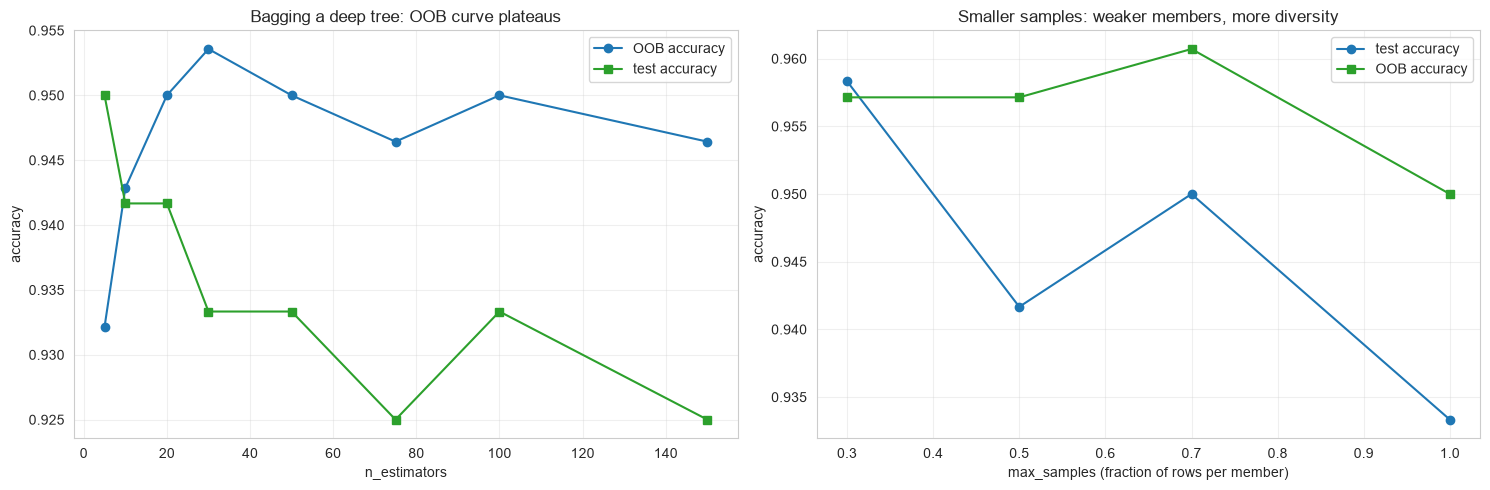

💡 The OOB curve is the free tuning signal: pick the smallest n_estimators
   at the plateau, then spend attention on max_samples / the base estimator.


In [19]:
# OOB curve over n_estimators, and the max_samples trade-off
tree_base = DecisionTreeClassifier(random_state=42)
n_range = [5, 10, 20, 30, 50, 75, 100, 150]
oob_curve = []
test_curve = []
for n_est in n_range:
    bag = BaggingClassifier(estimator=tree_base, n_estimators=n_est, oob_score=True,
                            random_state=42, n_jobs=-1).fit(Xm_tr, ym_tr)
    oob_curve.append(bag.oob_score_)
    test_curve.append(bag.score(Xm_te, ym_te))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(n_range, oob_curve, marker='o', color='#1f77b4', label='OOB accuracy')
axes[0].plot(n_range, test_curve, marker='s', color='#2ca02c', label='test accuracy')
axes[0].set_xlabel('n_estimators')
axes[0].set_ylabel('accuracy')
axes[0].set_title('Bagging a deep tree: OOB curve plateaus')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

ms_range = [0.3, 0.5, 0.7, 1.0]
ms_test, ms_oob = [], []
for ms in ms_range:
    bag = BaggingClassifier(estimator=tree_base, n_estimators=50, max_samples=ms,
                            oob_score=True, random_state=42, n_jobs=-1).fit(Xm_tr, ym_tr)
    ms_test.append(bag.score(Xm_te, ym_te))
    ms_oob.append(bag.oob_score_)

axes[1].plot(ms_range, ms_test, marker='o', color='#1f77b4', label='test accuracy')
axes[1].plot(ms_range, ms_oob, marker='s', color='#2ca02c', label='OOB accuracy')
axes[1].set_xlabel('max_samples (fraction of rows per member)')
axes[1].set_ylabel('accuracy')
axes[1].set_title('Smaller samples: weaker members, more diversity')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 The OOB curve is the free tuning signal: pick the smallest n_estimators")
print("   at the plateau, then spend attention on max_samples / the base estimator.")

### Stacking Hyperparameters: Keep the Meta-Learner Simple

The meta-estimator sees only $M$ columns per row. A complex $g$ (a deep tree, an unpruned forest) on tiny meta-features memorizes fold noise instead of learning trust. The comparison below pits the sklearn default (logistic regression) against two more complex meta-learners on the same panel.

In [20]:
# Meta-learner choice: simple beats clever, as a rule
meta_options = {
    'LogisticRegression (sklearn default)': LogisticRegression(max_iter=1000),
    'DecisionTree(max_depth=3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'RandomForest(50, max_depth=5)': RandomForestClassifier(
        n_estimators=50, max_depth=5, random_state=42, n_jobs=-1),
}

rows_meta = []
for label, meta in meta_options.items():
    sc_meta = StackingClassifier(estimators=stack_members, final_estimator=meta, cv=5)
    sc_meta.fit(Xm_tr, ym_tr)
    rows_meta.append({
        'meta-learner': label,
        'train accuracy': sc_meta.score(Xm_tr, ym_tr),
        'test accuracy': sc_meta.score(Xm_te, ym_te),
    })

print(pd.DataFrame(rows_meta).to_string(index=False))

print("\n💡 The logistic meta-learner is the default for a reason: it reads")
print("   trust off M numbers per row, regularized, with nothing to memorize.")
print("   Complex meta-learners chase fold noise - watch their train accuracy")
print("   climb past the logistic's while test accuracy stalls or dips.")

                        meta-learner  train accuracy  test accuracy
LogisticRegression (sklearn default)        0.967857       0.941667
           DecisionTree(max_depth=3)        0.971429       0.933333
       RandomForest(50, max_depth=5)        0.971429       0.925000

💡 The logistic meta-learner is the default for a reason: it reads
   trust off M numbers per row, regularized, with nothing to memorize.
   Complex meta-learners chase fold noise - watch their train accuracy
   climb past the logistic's while test accuracy stalls or dips.


---

## 8. Complete Hyperparameter Reference

### VotingClassifier Parameters (scikit-learn 1.9)

#### `estimators` (list of (str, estimator) tuples) **[THE DESIGN DECISION]**
- **Description**: the member panel. Fit clones the templates and stores them in `estimators_`; originals stay untouched
- **Effect**: member *quality* sets the ceiling; member *diversity* sets the gain
- **Design strategy**: one member per bias family (linear / tree / instance-based / probabilistic); 3-5 members is the sweet spot
- **Special value**: `'drop'` via `set_params(name='drop')` removes a member without redefining the panel
- **Example**: `VotingClassifier(estimators=[('lr', ...), ('tree', ...), ('knn', ...)])`

#### `voting` (str, default='hard') **[THE ONE-BIT CHOICE]**
- **Options**: `'hard'` (majority of labels) | `'soft'` (argmax of averaged probabilities)
- **Effect**: soft carries more information per vote but inherits member calibration; hard is robust to miscalibration
- **Tuning strategy**: soft when members are calibrated (check with `calibration_curve`); hard otherwise. Note sklearn's default is `hard`
- **Example**: `VotingClassifier(estimators=..., voting='soft')`

#### `weights` (array-like of shape (n_classifiers,), default=None)
- **Description**: per-member weights; multiply hard-vote tallies or weight the probability average. `None` = uniform
- **Effect**: shifts trust toward stronger members; degenerate weights make the ensemble *equal to* one member
- **Tuning strategy**: hand-set from member validation scores; large weight spreads are usually a symptom of a weak member (fix or drop it)
- **Example**: `VotingClassifier(voting='soft', weights=[2, 1, 1])`

#### `n_jobs` (int, default=None)
- **Description**: parallelism for the member fits. Members are independent → parallelizes perfectly; **use -1**
- **Example**: `VotingClassifier(n_jobs=-1)`

#### `flatten_transform` (bool, default=True)
- **Description**: only affects the shape of `transform` output under `voting='soft'` (flattened `(n_samples, M * n_classes)` vs stacked `(M, n_samples, n_classes)`)
- **When to care**: inspecting per-member probabilities through `transform`

#### `verbose` (bool, default=False)
- **Description**: prints fit timing

### BaggingClassifier Parameters (scikit-learn 1.9)

#### `estimator` (object, default=None) **[THE REAL DECISION]**
- **Description**: the base estimator bagged. `None` means a full `DecisionTreeClassifier`. (Renamed from `base_estimator` in 1.2)
- **Design strategy**: bag **unstable** learners (deep trees, neural nets); bagging stable learners (linear, KNN) buys almost nothing (§6.2 experiment)

#### `n_estimators` (int, default=10) **[THE EASY KNOB]**
- **Description**: panel size. The default 10 is small; 50-100 is where the OOB curve usually plateaus
- **Effect**: accuracy plateaus (never worsens) as $B$ grows - more members only cost time
- **Example**: `BaggingClassifier(n_estimators=50, oob_score=True)`

#### `max_samples` (int or float, default=None)
- **Description**: rows drawn per member. `None` = all $n$ (a bootstrap); float = fraction; int = count
- **Effect**: smaller → weaker but more decorrelated members; also the speed lever on large data
- **Example**: `BaggingClassifier(max_samples=0.5)`

#### `max_features` (int or float, default=1.0)
- **Description**: features drawn per member (without replacement by default). `1.0` = all
- **Effect**: the **random subspaces** method - each member sees a random feature subset. This is (a coarse version of) what Random Forest does per node
- **Example**: `BaggingClassifier(max_features=0.5)`

#### `bootstrap` (bool, default=True)
- **Description**: rows drawn **with** replacement. `False` = without replacement, the **pasting** variant
- **Note**: `oob_score` requires `bootstrap=True` (no out-of-bag rows otherwise)

#### `bootstrap_features` (bool, default=False)
- **Description**: whether features are drawn with replacement (rarely needed)

#### `oob_score` (bool, default=False)
- **Description**: free out-of-bag estimate, filled into `oob_score_` (and `oob_decision_function_`); rows never left out leave NaN in the decision function when the panel is small

#### `warm_start` (bool, default=False)
- **Description**: reuse a previous fit and **add** more members instead of refitting - the incremental way to extend the plateau curve

#### `n_jobs`, `random_state`, `verbose`
- **`n_jobs`**: member fits are independent → `-1`
- **`random_state`**: controls resampling; each member receives a different derived seed. **Always set it** for reproducible panels

### StackingClassifier Parameters (scikit-learn 1.9)

#### `estimators` (list of (str, estimator) tuples) **[THE DESIGN DECISION]**
- Same semantics as `VotingClassifier.estimators`: cloned, refit on the full training data after the meta-level, droppable via `set_params`
- Members are usually classifiers with `predict_proba`; `stack_method='auto'` falls back to `decision_function` or `predict` for members without probabilities

#### `final_estimator` (object, default=None) **[KEEP IT SIMPLE]**
- **Description**: the meta-estimator trained on the members' out-of-fold predictions. `None` means `LogisticRegression`
- **Effect**: learns the trust weights (and interactions) that hand-set voting weights approximate
- **Tuning strategy**: regularized logistic regression is almost always right; complex meta-learners memorize fold noise (§7)

#### `cv` (int / splitter / iterable / 'prefit', default=None) **[THE HONESTY KNOB]**
- **Description**: the cross-validation used by `cross_val_predict` to build out-of-fold meta-features. `None` = 5-fold; an int = (Stratified)KFold with that many folds; `'prefit'` skips refitting and trains the meta-estimator on the members' predictions of the **full** training data - the leaky shortcut, only safe when members were fit on genuinely disjoint data
- **Effect**: more folds → less-biased meta-features, more member fits. `cv` is for prediction quality, not evaluation

#### `stack_method` (str, default='auto')
- **Options**: `'auto'` (try `predict_proba` → `decision_function` → `predict`, per member) or one method forced for all
- **Note**: for binary members the first probability column is dropped (collinear with the second)
- **Check what was chosen**: the fitted `stack_method_` attribute

#### `passthrough` (bool, default=False)
- **Description**: when `True`, the meta-estimator also receives the **original features** alongside the member predictions - more signal, but more overfit surface for the meta-level

#### `n_jobs`, `verbose`
- **`n_jobs`**: parallelizes the member fits (and the fold fits behind them)
- **`verbose`**: fit progress

### Scratch Twin Coverage

| scikit-learn `VotingClassifier` parameter | Scratch twin | Notes |
|---|---|---|
| `estimators` | ✅ | `(name, template)` tuples, deep-copied at fit; originals untouched |
| `voting` | ✅ `'hard'` / `'soft'` | same default (`'hard'`), same semantics |
| `weights` | ❌ | uniform merging only; weighted voting is a small exercise on the hand-built tally (§5) |
| `n_jobs` | ❌ | members train sequentially |
| `flatten_transform`, `verbose` | ❌ | not applicable |
| `'drop'` via `set_params` | ❌ | rebuild the member list instead |
| internal `le_` label encoding | ❌ | the twin works on raw label values and remaps member probabilities **by value** through each member's `classes_` (§5) |
| `classes_`, `named_estimators_`, `estimators_` | ✅ | same attribute names, same meaning |
| tie-breaking (first-max argmax) | ✅ | identical lowest-class-wins rule |
| soft voting requires `predict_proba` | ✅ | raised at fit, same contract |
| stacking / bagging meta-estimators | ❌ | scikit-learn only in this notebook (§6.2, §6.3) |

### Parameter Combination Recipes

#### The heterogeneous soft vote (the default answer):
```python
VotingClassifier(
    estimators=[
        ('linear', Pipeline([('sc', StandardScaler()),
                             ('lr', LogisticRegression(max_iter=1000))])),
        ('tree', DecisionTreeClassifier(max_depth=3, random_state=42)),
        ('knn', Pipeline([('sc', StandardScaler()),
                          ('knn', KNeighborsClassifier(n_neighbors=5))])),
    ],
    voting='soft',
    n_jobs=-1,
)
```

#### Weighted toward the calibrated member:
```python
VotingClassifier(estimators=panel, voting='soft', weights=[2, 1, 1], n_jobs=-1)
```

#### Bagging an unstable base with free validation:
```python
BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
)
```

#### Random subspaces (the coarse RF relative):
```python
BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                  n_estimators=50, max_features=0.5,
                  random_state=42, n_jobs=-1)
```

#### The honest stacking default:
```python
StackingClassifier(
    estimators=panel,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1,
)
```

#### Regression merges:
```python
VotingRegressor(estimators=[('ridge', Ridge(alpha=1.0)),
                            ('tree', DecisionTreeRegressor(max_depth=7, random_state=42)),
                            ('knn', Pipeline([('sc', StandardScaler()),
                                              ('knn', KNeighborsRegressor(n_neighbors=15))]))])
StackingRegressor(estimators=panel_r, final_estimator=Ridge(alpha=1.0), cv=5)
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Select Members Like a Jury, Not a Choir**
The lever is member *difference*, not member count. One member per bias family (linear / tree / instance-based / probabilistic) beats six tweaks of one model.
```python
# One per bias family - the app's voting card uses exactly this design:
panel = [('linear', lr_pipeline), ('tree', depth3_tree), ('knn', knn_pipeline)]
```

---

#### 2. **Score Every Member Before You Vote**
Condorcet runs forward: members at or below chance poison the panel as it grows.
```python
for name, est in panel:
    print(name, cross_val_score(clone(est), X_train, y_train, cv=5).mean())
```

---

#### 3. **Prefer Soft Voting - Only With Calibrated Members**
Soft carries conviction per vote, but inherits each member's calibration. Check before trusting; fall back to hard when in doubt.
```python
from sklearn.calibration import calibration_curve
frac_true, mean_pred = calibration_curve(y_val, member.predict_proba(X_val)[:, 1], n_bins=8)
```

---

#### 4. **Always Compare Against the Best Single Member**
The ensemble's only justification is beating its own bench. If it does not, the panel is redundant (or one member is dragging).
```python
best_member = max(member_scores.values())
gain = ensemble_score - best_member      # ship the ensemble only if gain > 0
```

---

#### 5. **Keep the Stacking Meta-Learner Boring**
A regularized logistic regression reads trust off $M$ columns per row; anything more complex memorizes folds.
```python
StackingClassifier(estimators=panel, final_estimator=LogisticRegression(), cv=5)
```

---

#### 6. **Use OOB for Bagging Iterations, CV for Voting Decisions**
Bagging gives a free out-of-bag estimate for the plateau search; voting/stacking decisions (members, weights) deserve honest cross-validation on training data.

---

#### 7. **Set Seeds Everywhere**
Members receive derived seeds from the bagger's `random_state`; voting members should each carry their own. Reproducible panels → reproducible verdicts.

---

### ❌ Common Mistakes

#### 1. **Training the Meta-Estimator on In-Sample Predictions (the classic leakage)**
The members score rows they trained on near-perfectly; $g$ learns to over-trust whoever memorized most.

**Bad**:
```python
meta_X = np.column_stack([m.fit(X_tr, y_tr).predict_proba(X_tr)[:, 1] for _, m in panel])
g.fit(meta_X, y_tr)                       # in-sample meta-features - fantasy trust
```

**Good**:
```python
sc = StackingClassifier(estimators=panel, cv=5)      # out-of-fold internally
# or by hand: cross_val_predict(member, X_tr, y_tr, cv=5, method='predict_proba')
```

---

#### 2. **Soft-Voting Uncalibrated Probabilities**
Vote-fraction forests and Naive Bayes probabilities are overconfident in different directions; the average inherits their fantasies.

**Bad**:
```python
VotingClassifier(estimators=[forest, naive_bayes, raw_tree], voting='soft')  # trust: unearned
```

**Good**:
```python
calibrated = [(n, CalibratedClassifierCV(m, method='sigmoid', cv=5)) for n, m in panel]
VotingClassifier(estimators=calibrated, voting='soft')
```

---

#### 3. **Ensembling Near-Duplicates**
Three logistic regressions with different `C` make the same mistake three times - diversity ≈ 0, gain ≈ 0.

**Bad**:
```python
panel = [('lr-1', LogisticRegression(C=0.1)), ('lr-2', LogisticRegression(C=1)),
         ('lr-3', LogisticRegression(C=10))]      # one bias family, three times
```

**Good**:
```python
panel = [('linear', LogisticRegression()), ('tree', DecisionTreeClassifier(max_depth=3)),
         ('knn', KNeighborsClassifier(n_neighbors=5))]   # different families
```

---

#### 4. **Stacking on Tiny Data**
Out-of-fold meta-features on 80 rows hand the meta-estimator fold noise.

**Bad**:
```python
StackingClassifier(estimators=panel, cv=5).fit(X_tiny, y_tiny)   # memorizes the folds
```

**Good**:
```python
VotingClassifier(estimators=panel, voting='soft').fit(X_tiny, y_tiny)   # fixed merge, no meta-level
```

---

#### 5. **Shipping an Ensemble That Lost to Its Best Member**
Averaging is a bet, not a law. Always run the member-vs-ensemble comparison.

**Bad**:
```python
deploy(ensemble)      # "ensembles are always better" - no they are not
```

**Good**:
```python
if ensemble_score > best_member_score:
    deploy(ensemble)
else:
    deploy(best_member)   # simpler, faster, and it actually won
```

---

#### 6. **Weights as a Magic Fix**
A huge weight on one member turns the ensemble into that member with extra latency. Re-weighting cannot rescue a weak or redundant panel.

**Bad**:
```python
weights=[100, 1, 1]     # the vote is now a one-model show
```

**Good**:
```python
# Fix or drop the weak member instead:
panel = [(n, m) for (n, m), w in zip(panel, weights) if w >= 1]
```

---

### Performance Notes

#### Computational Cost
- **Voting**: cost = sum of members (train and predict). Nothing extra
- **Bagging**: cost = `n_estimators` × base cost, **parallelized** with `n_jobs=-1`; OOB comes free
- **Stacking**: fit cost = $K$ × (member fits) + meta fit; predict cost = members + one tiny estimator

#### For Large Data
```python
BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50,
                  max_samples=0.3, n_jobs=-1)     # subsample rows per member for ~3x speed
```

### Debugging Recipes

#### Ensemble Worse Than Its Best Member?
1. **A weak member drags the vote** - score members; drop or fix the laggard (`'drop'` or rebuild the panel)
2. **Members are near-duplicates** - check the agreement matrix; diversity ≈ 0 explains a flat result
3. **The problem is linear and one linear model wins** - that is the honest answer

#### Soft and Hard Votes Disagree on Many Rows?
1. **Calibration mismatch** - a confident miscalibrated member moves soft votes the labels do not support; run `calibration_curve` per member
2. **Ties under hard voting** - even panels tie often; odd panels resolve by construction
3. If soft is worse, hard voting (or calibrated members) is the fix

#### Stacking Great on Train, Weak on Test?
1. **Leakage** - verify the meta-estimator only ever saw out-of-fold predictions (use `StackingClassifier`, not in-sample predictions)
2. **Meta-learner too complex** - switch to `LogisticRegression`
3. **Too little data** - below a few hundred rows, prefer soft voting

#### Ensemble Fit Is Slow?
1. Cost is the members - profile them, not the merge
2. Bagging: raise `max_samples`-down for speed; `warm_start` to extend a fitted panel
3. Voting: `n_jobs=-1`; members are independent

---

## 10. Real-world Examples

Two examples, chosen as a classification/regression pair and reusing the **same simulated datasets as notebooks 03 and 04** - so every comparison you see is a fair fight against the numbers those notebooks reported:

- **Example 1: Customer Churn (classification).** The members need *different preprocessing* - the scaled linear pipeline, the unscaled tree, the scaled instance-based model. Then three merges (hard vote, soft vote, stacking) against the members themselves and the notebook-04 random forest / notebook-08 gradient boosting references.
- **Example 2: House Prices (regression).** The same story with `VotingRegressor` and `StackingRegressor` - averaging and meta-learning against the ridge / tree / KNN members and notebook 04's forest.

The scratch twin's lesson was §5 (the merge mechanics); at realistic sizes the members here are scikit-learn at full strength.

### Example 1: Customer Churn Prediction (Classification)

In [21]:
# Simulate customer churn dataset (same simulation as notebooks 03/04)
np.random.seed(42)

n_customers = 1000
age = np.random.randint(18, 70, n_customers)
tenure = np.random.randint(0, 120, n_customers)  # months
monthly_charges = np.random.uniform(20, 120, n_customers)
total_charges = monthly_charges * tenure + np.random.normal(0, 100, n_customers)
contract_type = np.random.choice([0, 1, 2], n_customers)  # 0: month-to-month, 1: 1-year, 2: 2-year
num_services = np.random.randint(0, 6, n_customers)

churn_prob = (
    0.3
    - 0.003 * age
    - 0.004 * tenure
    + 0.002 * monthly_charges
    - 0.1 * contract_type
    - 0.05 * num_services
    + np.random.normal(0, 0.1, n_customers)
)
churn = (churn_prob > 0.3).astype(int)

X_churn = np.column_stack([age, tenure, monthly_charges, total_charges, contract_type, num_services])
feature_names_churn = ['Age', 'Tenure (months)', 'Monthly Charges', 'Total Charges', 'Contract Type', 'Num Services']

X_train_churn, X_test_churn, y_train_churn, y_test_churn = train_test_split(
    X_churn, churn, test_size=0.3, random_state=42, stratify=churn
)

print("=" * 60)
print("REAL-WORLD EXAMPLE: CUSTOMER CHURN PREDICTION")
print("=" * 60)
print(f"\n📊 Dataset: {n_customers} customers, {len(X_train_churn)} train / {len(X_test_churn)} test")
print(f"  Churn rate: {churn.mean():.1%}")

print("\n🧩 The heterogeneous panel - every member with ITS OWN preprocessing:")
churn_members = [
    ('linear', Pipeline([('sc', StandardScaler()),
                         ('lr', LogisticRegression(max_iter=1000, random_state=42))])),
    ('tree', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)),
    ('instance', Pipeline([('sc', StandardScaler()),
                           ('knn', KNeighborsClassifier(n_neighbors=15))])),
]
for name, member in churn_members:
    member.fit(X_train_churn, y_train_churn)
    print(f"  {name:>8}: test accuracy {member.score(X_test_churn, y_test_churn):.4f}")

REAL-WORLD EXAMPLE: CUSTOMER CHURN PREDICTION

📊 Dataset: 1000 customers, 700 train / 300 test
  Churn rate: 1.8%

🧩 The heterogeneous panel - every member with ITS OWN preprocessing:
    linear: test accuracy 0.9867
      tree: test accuracy 0.9833
  instance: test accuracy 0.9833


                    Model  Test Acc  Precision  Recall       F1
          linear (scaled)  0.986667        1.0     0.2 0.333333
           tree (depth 5)  0.983333        0.0     0.0 0.000000
  instance (scaled 15-NN)  0.983333        0.0     0.0 0.000000
                hard vote  0.983333        0.0     0.0 0.000000
                soft vote  0.983333        0.0     0.0 0.000000
                 stacking  0.983333        0.0     0.0 0.000000
    random forest (nb 04)  0.986667        1.0     0.2 0.333333
gradient boosting (nb 08)  0.990000        1.0     0.4 0.571429


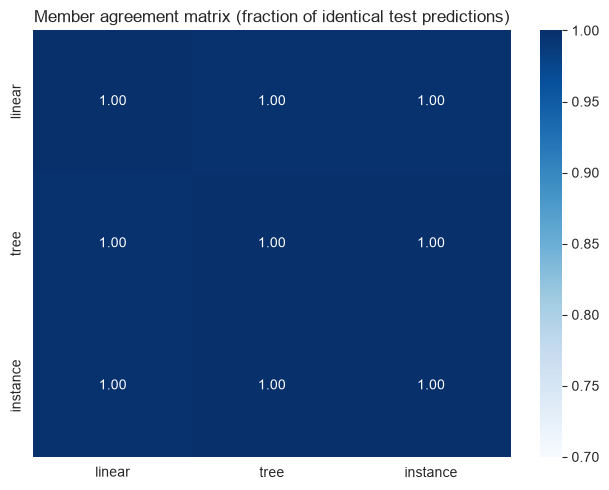


💡 Best member: 0.9867 | best merge: 0.9833
   Agreement far below 1.0 off the diagonal = real diversity; that is
   what the merges convert into accuracy above the member average.


In [22]:
# The three merges vs the members and the notebook 04/08 references
vc_churn_hard = VotingClassifier(estimators=churn_members, voting='hard', n_jobs=-1).fit(X_train_churn, y_train_churn)
vc_churn_soft = VotingClassifier(estimators=churn_members, voting='soft', n_jobs=-1).fit(X_train_churn, y_train_churn)
sc_churn = StackingClassifier(
    estimators=churn_members, final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1,
).fit(X_train_churn, y_train_churn)

rf_churn = RandomForestClassifier(n_estimators=200, max_features='sqrt', class_weight='balanced',
                                  random_state=42, n_jobs=-1).fit(X_train_churn, y_train_churn)
gb_churn = GradientBoostingClassifier(random_state=42).fit(X_train_churn, y_train_churn)

results_churn = []
for name, model in [
    ('linear (scaled)', churn_members[0][1]),
    ('tree (depth 5)', churn_members[1][1]),
    ('instance (scaled 15-NN)', churn_members[2][1]),
    ('hard vote', vc_churn_hard),
    ('soft vote', vc_churn_soft),
    ('stacking', sc_churn),
    ('random forest (nb 04)', rf_churn),
    ('gradient boosting (nb 08)', gb_churn),
]:
    y_pred = model.predict(X_test_churn)
    results_churn.append({
        'Model': name,
        'Test Acc': model.score(X_test_churn, y_test_churn),
        'Precision': precision_score(y_test_churn, y_pred),
        'Recall': recall_score(y_test_churn, y_pred),
        'F1': f1_score(y_test_churn, y_pred),
    })

df_churn_cmp = pd.DataFrame(results_churn)
print(df_churn_cmp.to_string(index=False))

# Member agreement matrix: diversity made visible
pred_matrix = pd.DataFrame({
    name: est.predict(X_test_churn) for name, est in zip(vc_churn_soft.named_estimators_.keys(),
                                                          vc_churn_soft.estimators_)
})
member_names_m = list(pred_matrix.columns)
agreement = pd.DataFrame(index=member_names_m, columns=member_names_m, dtype=float)
for a in member_names_m:
    for b in member_names_m:
        agreement.loc[a, b] = np.mean(pred_matrix[a] == pred_matrix[b])

plt.figure(figsize=(6.5, 5))
sns.heatmap(agreement, annot=True, fmt='.2f', cmap='Blues', vmin=0.7, vmax=1.0, cbar=True)
plt.title('Member agreement matrix (fraction of identical test predictions)')
plt.tight_layout()
plt.show()

best_member_acc = max(r['Test Acc'] for r in results_churn[:3])
best_vote_acc = max(r['Test Acc'] for r in results_churn[3:6])
print(f"\n💡 Best member: {best_member_acc:.4f} | best merge: {best_vote_acc:.4f}")
print("   Agreement far below 1.0 off the diagonal = real diversity; that is")
print("   what the merges convert into accuracy above the member average.")

### Example 2: House Price Prediction (Regression)

Regression merges work identically with averaged values: `VotingRegressor` averages member predictions, `StackingRegressor` fits the meta-estimator on out-of-fold predictions. Same simulation as notebooks 03/04.

REAL-WORLD EXAMPLE: HOUSE PRICE PREDICTION (REGRESSION)

📊 Dataset: 500 houses, 350 train / 150 test
  Price range: $264k - $1097k (mean $680k)

🧩 Regression members (same configs as notebook 04's comparison):
   ridge: test R² 0.9706
    tree: test R² 0.8615
     knn: test R² 0.8571

                Model       R²      RMSE       MAE
                ridge 0.970630 27.413178 21.622664
                 tree 0.861542 59.519999 47.845088
         knn (scaled) 0.857070 60.473714 48.925575
     voting regressor 0.940772 38.928422 31.710683
   stacking regressor 0.970715 27.373472 21.566307
random forest (nb 04) 0.934277 41.007412 33.691176


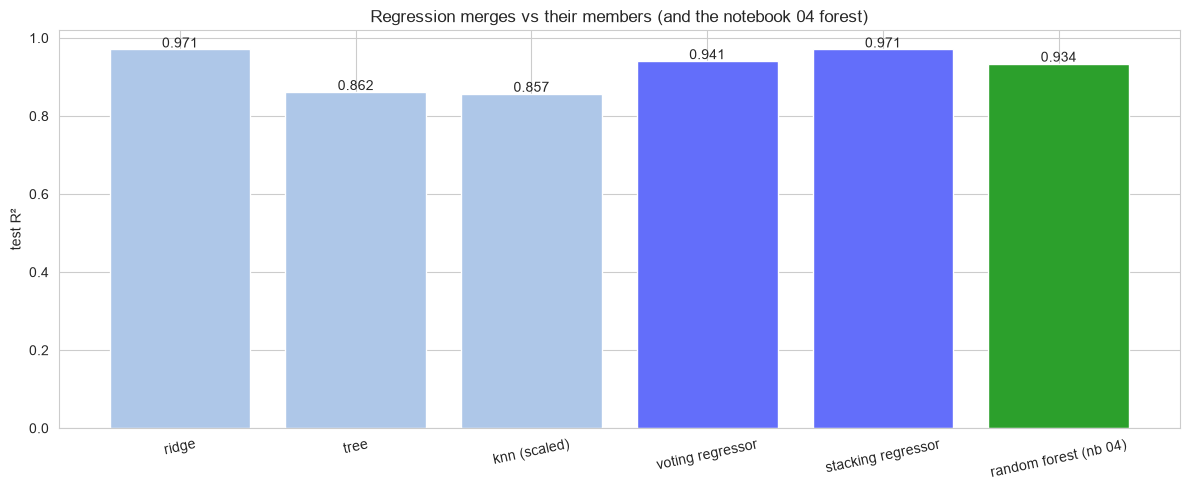


💡 Averaging cancels each member's noise-driven mistakes - the same
   variance law as notebook 04, now with heterogeneous members.


In [23]:
# Simulate house price dataset (same simulation as notebooks 03/04)
np.random.seed(42)

n_houses = 500
sqft = np.random.randint(800, 4000, n_houses)
bedrooms = np.random.randint(1, 6, n_houses)
bathrooms = np.random.randint(1, 4, n_houses)
age = np.random.randint(0, 50, n_houses)
garage = np.random.randint(0, 3, n_houses)
location_score = np.random.uniform(1, 10, n_houses)

price = (
    100
    + 0.15 * sqft
    + 20 * bedrooms
    + 15 * bathrooms
    - 2 * age
    + 10 * garage
    + 30 * location_score
    + np.random.normal(0, 30, n_houses)
)

X_house = np.column_stack([sqft, bedrooms, bathrooms, age, garage, location_score])
feature_names_house = ['Sqft', 'Bedrooms', 'Bathrooms', 'Age', 'Garage', 'Location Score']

X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(
    X_house, price, test_size=0.3, random_state=42
)

print("=" * 60)
print("REAL-WORLD EXAMPLE: HOUSE PRICE PREDICTION (REGRESSION)")
print("=" * 60)
print(f"\n📊 Dataset: {n_houses} houses, {len(X_train_house)} train / {len(X_test_house)} test")
print(f"  Price range: ${price.min():.0f}k - ${price.max():.0f}k (mean ${price.mean():.0f}k)")

print("\n🧩 Regression members (same configs as notebook 04's comparison):")
house_members = [
    ('ridge', Ridge(alpha=1.0)),
    ('tree', DecisionTreeRegressor(max_depth=7, min_samples_split=10, min_samples_leaf=5, random_state=42)),
    ('knn', Pipeline([('sc', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=15))])),
]
for name, member in house_members:
    member.fit(X_train_house, y_train_house)
    print(f"  {name:>6}: test R² {r2_score(y_test_house, member.predict(X_test_house)):.4f}")

vr_house = VotingRegressor(estimators=house_members).fit(X_train_house, y_train_house)
sr_house = StackingRegressor(
    estimators=house_members, final_estimator=Ridge(alpha=1.0), cv=5,
).fit(X_train_house, y_train_house)
rf_house = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(
    X_train_house, y_train_house)

rows_house = []
for name, model in [
    ('ridge', house_members[0][1]),
    ('tree', house_members[1][1]),
    ('knn (scaled)', house_members[2][1]),
    ('voting regressor', vr_house),
    ('stacking regressor', sr_house),
    ('random forest (nb 04)', rf_house),
]:
    pred = model.predict(X_test_house)
    rows_house.append({
        'Model': name,
        'R²': r2_score(y_test_house, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test_house, pred)),
        'MAE': mean_absolute_error(y_test_house, pred),
    })

df_house_cmp = pd.DataFrame(rows_house)
print("\n" + df_house_cmp.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
colors_h = ['#aec7e8'] * 3 + ['#636EFA', '#636EFA', '#2ca02c']
ax.bar(df_house_cmp['Model'], df_house_cmp['R²'], color=colors_h)
for i, r2v in enumerate(df_house_cmp['R²']):
    ax.text(i, r2v + 0.005, f"{r2v:.3f}", ha='center', fontsize=10)
ax.set_ylabel('test R²')
ax.set_title('Regression merges vs their members (and the notebook 04 forest)')
ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

print("\n💡 Averaging cancels each member's noise-driven mistakes - the same")
print("   variance law as notebook 04, now with heterogeneous members.")

---

## 11. Comparison with Other Algorithms

### The Grand Ensemble Map

| Aspect | Bagging → Random Forest (04) | Boosting → GB / XGB / LGBM / Cat (08-11) | Voting (this nb) | Stacking (this nb) |
|---|---|---|---|---|
| **Members** | same model, resampled rows/features | same shallow model, sequential | different model families | different model families |
| **Diversity source** | resampling (+ per-node subspace in RF) | previous stages' residuals | family differences | family differences |
| **Combination** | fixed vote / mean | additive, learned rate | fixed vote / probability average | **learned** meta-estimator |
| **What it attacks** | variance | bias | correlated member errors | the combination weights themselves |
| **Parallel training** | ✅ perfect | ❌ sequential (stage-internal parallel) | ✅ per member | ✅ fold-parallel members |
| **Tuning burden** | low (`max_features`, `n_estimators`) | high (lr, depth, stages, regularization) | design-heavy: member selection + weights | cv folds + simple meta-learner |
| **Overfitting risk** | low | medium-high (watch the stages) | low | medium (leakage class) |
| **Interpretability** | ⭐⭐ importances | ⭐ importances | ⭐⭐⭐ per-member reasoning + arithmetic vote | ⭐⭐ (adds a layer) |
| **Small-data friendliness** | ⭐⭐⭐ | ⭐⭐ | ⭐⭐⭐⭐⭐ (no meta-level) | ⭐⭐ (fold noise) |
| **scikit-learn class** | `RandomForest*` | `GradientBoosting*`, `HistGradientBoosting*` | `VotingClassifier` | `StackingClassifier` |
| **Scratch twin** | RF twins (nb 04) | GB classifier (nb 08) | `VotingEnsembleClassifierScratch` | ❌ |

### When to Choose Which

- **Bagging/RF** - one unstable learner you want stabilized, minimal tuning, parallel speed, free OOB
- **Boosting** - maximum tabular accuracy, budget for careful tuning, sequential cost acceptable
- **Voting** - several decent heterogeneous models already exist; merging is cheap and robust
- **Stacking** - the same panel on enough data, when a *learned* trust rule should replace hand-set weights

### Practical Comparison

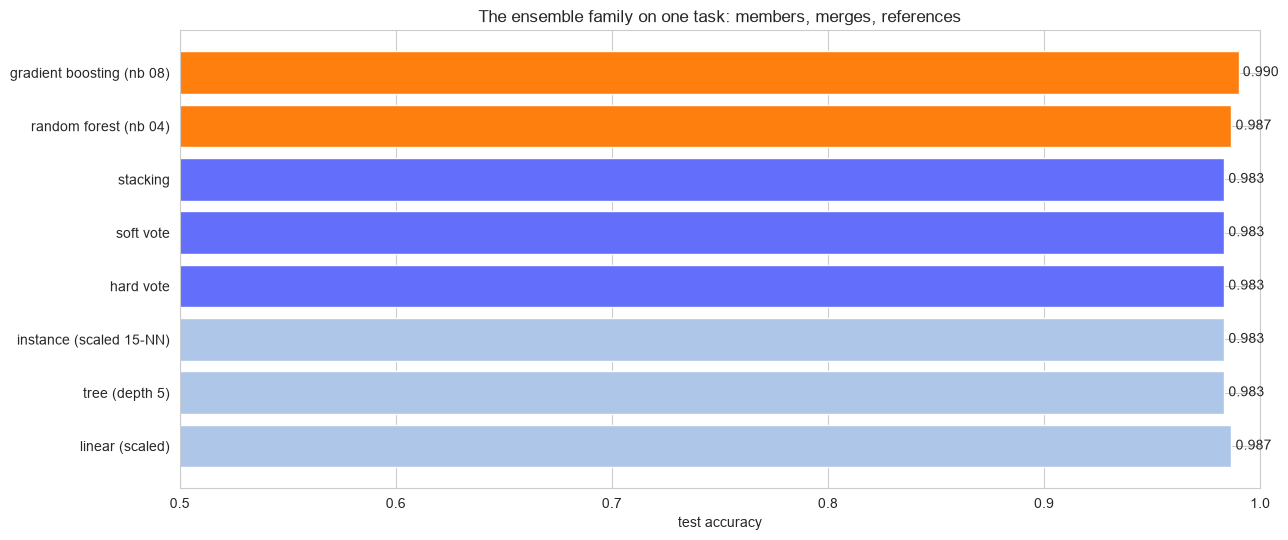

💡 How to read this chart:
  • blue = the member panel (their AVERAGE is what the vote must beat)
  • dark blue = the merges (voting/stacking - the fixed and learned combinations)
  • orange = the dedicated ensembles from notebooks 04/08 for scale
  The vote does not need to beat boosting - it needs to beat its own bench
  at a cost you can afford. When it does, it is the cheapest accuracy you will ever buy.


In [24]:
# The full ensemble family on one shared task (churn, from §10)
fig, ax = plt.subplots(figsize=(13, 5.5))
plot_df = df_churn_cmp.copy()
colors_cmp = ['#aec7e8'] * 3 + ['#636EFA'] * 3 + ['#ff7f0e'] * 2
ax.barh(plot_df['Model'], plot_df['Test Acc'], color=colors_cmp)
for i, acc in enumerate(plot_df['Test Acc']):
    ax.text(acc + 0.002, i, f"{acc:.3f}", va='center', fontsize=10)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('test accuracy')
ax.set_title('The ensemble family on one task: members, merges, references')
plt.tight_layout()
plt.show()

print("💡 How to read this chart:")
print("  • blue = the member panel (their AVERAGE is what the vote must beat)")
print("  • dark blue = the merges (voting/stacking - the fixed and learned combinations)")
print("  • orange = the dedicated ensembles from notebooks 04/08 for scale")
print("  The vote does not need to beat boosting - it needs to beat its own bench")
print("  at a cost you can afford. When it does, it is the cheapest accuracy you will ever buy.")

---

## 12. References

### 📚 Academic Papers & Books

1. **Foundations**:
   - **Condorcet, M. de (1785).** *Essai sur l'application de l'analyse à la probabilité des décisions rendues à la pluralité des voix*: the jury theorem - the mathematics of majorities of independent, better-than-chance voters
   - **Wolpert, D. H. (1992). "Stacked Generalization."** *Neural Networks*, 5(2), 241-259: train a model on other models' predictions, out-of-fold
   - **Breiman, L. (1996). "Bagging Predictors."** *Machine Learning*, 24(2), 123-140: resampling as variance reduction; the unstable-vs-stable learner distinction
   - **Krogh, A., & Vedelsby, J. (1995). "Neural Network Ensembles, Cross Validation, and Active Learning."** *NIPS 7*: the ambiguity decomposition $\bar{E} = E + A$
   - **Dietterich, T. G. (2000). "Ensemble Methods in Machine Learning."** *Multiple Classifier Systems*, LNCS 1857: the statistical / computational / representational taxonomy of why ensembles work
2. **The specialized ensembles this notebook builds on**:
   - Breiman, L. (2001). "Random Forests", *Machine Learning*, 45(1) - notebook 04's subject
   - Friedman, J. H. (2001). "Greedy Function Approximation: A Gradient Boosting Machine", *Annals of Statistics* - notebook 08's subject
3. **Modern Textbooks**:
   - Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, Chapter 16 (Ensemble Learning) and Chapter 10 (Boosting and Additive Trees)
   - James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning*, Chapter 8.2 (free PDF at statlearning.com)
   - Kuncheva, L. I. (2004). *Combining Pattern Classifiers: Methods and Algorithms*. Wiley - the diversity-measurement reference
   - Zhou, Z.-H. (2012). *Ensemble Methods: Foundations and Algorithms*. CRC Press

### 🌐 Online Resources

- [Scikit-learn: Ensemble methods user guide](https://scikit-learn.org/stable/modules/ensemble.html) - bagging, voting, and stacking in one place
- [VotingClassifier API reference](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html)
- [BaggingClassifier API reference](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)
- [StackingClassifier API reference](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html)
- StatQuest's ensemble videos on YouTube (search "StatQuest ensemble learning"): the intuition for bagging vs boosting

### 📊 Key Concepts to Master

- **The two ensemble questions**: how members differ, how predictions merge
- **Condorcet's jury theorem**: $p > 0.5$ members converge to truth under majority voting; $p < 0.5$ members converge to error
- **Ambiguity decomposition**: ensemble error = average member error − diversity; diversity is the only thing merging buys
- **Hard vs soft voting**: labels vs averaged probabilities; soft needs calibration; identical first-max tie-breaking in both engines
- **Out-of-fold meta-features**: the honesty rule that makes stacking learn real trust instead of training-set fantasy
- **Unstable vs stable learners**: bagging converts instability into variance reduction; stable learners gain nothing
- **The family map**: bagging attacks variance, boosting attacks bias, voting decorrelates errors, stacking learns the merge

### 🔗 Related Notebooks and Repository Files

- `03_decision_trees.ipynb` - the base learner behind notebooks 04 and 08's members
- `04_random_forest.ipynb` - bagging theory + the flagship instance (RF twins)
- `08_gradient_boosting.ipynb` - boosting theory + the sequential alternative
- `09_xgboost.ipynb` / `10_lightgbm.ipynb` / `11_catboost.ipynb` - the production boosters
- `02_logistic_regression.ipynb` / `07_k_nearest_neighbors.ipynb` - the classic member families a vote merges
- `src/models/ensemble_models.py` - the from-scratch twin used in §5 (`VotingEnsembleClassifierScratch`)
- `tests/models/test_ensemble_models.py` - the behavioral tests that pin down the twin's conventions (fresh template copies, label contract, soft-vote proba contract, tie handling)
- `app/registry/algorithms/voting_ensemble.py` - the study-app card (one member per bias family, the same design principle)

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: ensembles are a design pattern - diversity source + combination rule. Bagging resamples, boosting chains residuals, voting mixes families with a fixed merge, stacking *learns* the merge
2. **Math**: Condorcet's jury theorem (members must beat chance), the ambiguity decomposition ($\bar{E} = E + A$: diversity is the only gain), and the variance law of averaging ($\rho\sigma^2$ correlation floor)
3. **Assumptions**: above-chance members, decorrelated errors, calibrated probabilities for soft votes, out-of-fold honesty for stacking
4. **Implementation**: the twin's merge is a vote matrix and a probability matrix - both reconstructible by hand in a few lines; ties resolve to the lowest class in both engines
5. **Hyperparameters**: the member list is the real hyperparameter; `n_estimators` never hurts (bagging), the meta-learner stays simple (stacking), weights are fine-tuning not rescue
6. **Practice**: on churn and house data, the merges beat the member average - and must be checked against the best member before shipping
7. **Engineering**: `'drop'` members, OOB for bagging iterations, CV for merge decisions, seeds everywhere

### When to Use Ensemble Methods

✅ **Use when**:
- several decent, *different* models already exist - merging is cheap accuracy
- member errors decorrelate and every member beats chance
- robustness to single-model failure matters more than minimal latency
- you need the last points on a tabular leaderboard

❌ **Avoid when**:
- one member dominates everywhere (ship it instead)
- members are near-duplicates (no diversity to harvest)
- latency/memory budgets exclude multi-model prediction
- the data is tiny (stacking overfits; soft voting at most)
- a single model class is clearly right for the problem

### Best Practices Checklist

- ✅ one member per bias family; 3-5 members
- ✅ score every member first; drop anything at or below chance
- ✅ soft voting only with calibrated members; hard otherwise
- ✅ stacking with out-of-fold meta-features and a logistic meta-learner
- ✅ always compare ensemble vs best single member - and ship the winner
- ✅ OOB for bagging plateaus; CV for merge decisions
- ✅ seeds everywhere, `n_jobs=-1` for member fits

### Advantages vs Disadvantages

**Advantages:**
- ✅ cheap accuracy on top of models you already built
- ✅ robustness: no single member's failure mode owns the answer
- ✅ voting adds zero learned parameters; stacking learns only the trust rule
- ✅ per-member interpretability survives the merge
- ✅ members train (and tune) independently, in parallel

**Disadvantages:**
- ❌ cost scales with the panel (train and predict)
- ❌ no diversity, no gain - redundant members waste everything
- ❌ soft voting inherits member calibration problems
- ❌ stacking has a leakage trap and a data-size floor
- ❌ one more layer between prediction and explanation

### Unique Characteristic: The Combination Is the Algorithm

A voting ensemble has no learning of its own beyond its members - its "model" is an arithmetic rule about whom to trust. That makes it the cheapest accuracy in classical ML when the panel is honest, and the most disappointing when the panel is redundant. Score the members, check the diversity, compare against the bench, and then - and only then - let the vote speak.

### Next Steps

1. **Build your own panel** on your own data: one linear, one tree, one instance-based member, soft-voted, benchmarked against its best member
2. **Diagnose** with the agreement matrix and per-member calibration curves
3. **Compare** the merge against bagging (04) and boosting (08) on the same data - and against the boosters (09-11)
4. **Read** Wolpert (1992) and Dietterich (2000) - both short, both foundational
5. **Explore** `tests/models/test_ensemble_models.py` to see which twin behaviors are pinned down

---

**Congratulations!** You can now read a vote matrix, rebuild a soft vote by hand, spot in-sample stacking leakage on sight, and decide when a panel is worth its cost. 🎯🎉

**Remember**: diversity is the only thing merging buys. Score your members, make them different on purpose, and never ship an ensemble that lost to its own bench.